# Notebook 02 — Convolutional Autoencoder

## Chronology: architecture and normal-only pilot
This notebook begins Milestone 4. Development selection and the final benchmark
are **pending**. Notebook 01 and its artifacts remain unchanged. No autoencoder
official test evaluation has occurred. All numeric outputs below are from execution,
not checkpoint replay. Full local images/checkpoints remain outside Git.

An autoencoder learns an encoder $z=f_\theta(x)$ and decoder
$\hat{x}=g_\phi(z)$ that reproduce the input. Stride-two convolutions apply learned
local filters and halve spatial dimensions. The decoder doubles spatial dimensions
using bilinear interpolation and then learns convolutional filters. A linear 1x1
convolution creates the latent bottleneck; no skip connection bypasses it.

For a 256-square RGB input, an 8x32x32 bottleneck contains 8,192 values versus
196,608 input values (24-fold reduction in scalar count; this is not a bit-rate
or information-theoretic guarantee). L1 loss averages $|x-\hat{x}|$ over batch,
channels and pixels; MSE averages $(x-\hat{x})^2$ and emphasizes large residuals.
Training on fitting normals encourages reconstruction of normal structure.
Anomalies can nevertheless reconstruct well through shared local patterns or
excess capacity. Conversely, normal detail may reconstruct poorly. Blurring from
compression can produce residuals at normal edges; these are mechanisms to test,
not claims about unobserved final performance.

The predeclared development categories are bottle, cable, carpet and tile, chosen
for object/texture coverage without using official test performance. Bounded
ablation: shallow depth 3/latent 8/L1; depth 4; latent 2; latent 32; MSE.
One factor changes at a time. Combined loss, smoothing and a resolution change
require recorded development evidence first. Pilot: bottle, seed 2026, 256 pixels,
batch 16, Adam 0.001, three epochs, float32. No pretrained weights or augmentation.
Pilot epochs are a throughput check, not a selected final epoch budget.


In [1]:
from pathlib import Path
import sys, json, time, copy, traceback, subprocess
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from anomaly_detection.basic_cnn import seed_everything
from anomaly_detection.cnn_research import read_partition, require_fitting, load_resized
from anomaly_detection.data import sha256
from anomaly_detection.tracking import record
from anomaly_detection.autoencoder import ConvAutoencoder, reconstruction_loss, anomaly_map, image_scores
assert torch.cuda.is_available(), 'Pilot requires the existing CUDA environment'
torch.set_num_threads(4)
print(torch.__version__, torch.cuda.get_device_name(0))


Matplotlib is building the font cache; this may take a moment.


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


2.11.0+cu128 NVIDIA GeForce RTX 4060 Laptop GPU


## Actual architecture and scoring implementation
The following source is executed directly in the notebook. Channel-mean absolute
and squared residuals are separate candidate maps. A fixed top-1% mean aggregates each map into an image score; a maximum can be dominated by one noisy pixel.
Neither score is a probability. No smoothing is applied.

In [2]:
"""Scratch convolutional reconstruction baseline; RGB inputs/outputs in [0,1]."""
import math
import torch
from torch import nn
from torch.nn import functional as F


class ConvAutoencoder(nn.Module):
    """No skip connections: every reconstruction passes through the bottleneck.

    For depth=3, width=16, latent_channels=8 and 256-square inputs:
    encoder: B,3,256,256 -> B,16,128,128 -> B,32,64,64 -> B,64,32,32;
    bottleneck: B,8,32,32; decoder: B,32,64,64 -> B,16,128,128
    -> B,3,256,256. Bilinear upsampling followed by convolution avoids
    uneven transposed-convolution overlap. The final sigmoid bounds RGB.
    """
    def __init__(self, width=16, depth=3, latent_channels=8):
        super().__init__()
        if depth not in (3, 4) or width < 1 or latent_channels < 1:
            raise ValueError("Expected depth 3/4 and positive channel counts")
        self.divisor = 2 ** depth
        channels = [3] + [width * 2**i for i in range(depth)]
        layers = []
        for before, after in zip(channels, channels[1:]):
            layers.extend([nn.Conv2d(before, after, 3, 2, 1), nn.ReLU()])
        self.encoder = nn.Sequential(*layers)
        self.bottleneck = nn.Conv2d(channels[-1], latent_channels, 1)
        layers = []
        before = latent_channels
        for after in list(reversed(channels[1:-1])) + [3]:
            layers.extend([nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
                           nn.Conv2d(before, after, 3, padding=1),
                           nn.Sigmoid() if after == 3 else nn.ReLU()])
            before = after
        self.decoder = nn.Sequential(*layers)

    def forward(self, images):
        if images.ndim != 4 or images.shape[1] != 3 or any(s % self.divisor for s in images.shape[-2:]):
            raise ValueError("Expected B,3,H,W with spatial dimensions divisible by 2**depth")
        return self.decoder(self.bottleneck(self.encoder(images)))


def reconstruction_loss(reconstructed, target, kind="l1"):
    if reconstructed.shape != target.shape:
        raise ValueError("Reconstruction and target shapes must match")
    if kind == "l1":
        return F.l1_loss(reconstructed, target)
    if kind == "mse":
        return F.mse_loss(reconstructed, target)
    raise ValueError("Expected l1 or mse; combined losses require development justification")


def anomaly_map(images, reconstructed, kind="absolute"):
    if images.shape != reconstructed.shape or images.ndim != 4:
        raise ValueError("Matching B,C,H,W tensors required")
    difference = images.float() - reconstructed.float()
    if kind == "absolute":
        return difference.abs().mean(1)
    if kind == "squared":
        return difference.square().mean(1)
    raise ValueError("Expected absolute or squared")


def image_scores(maps, fraction=.01):
    """Fixed top-1% mean by default; independent of image/pixel thresholds."""
    if maps.ndim != 3 or not 0 < fraction <= 1:
        raise ValueError("Expected B,H,W maps and fraction in (0,1]")
    flat = maps.flatten(1)
    return flat.topk(max(1, math.ceil(flat.shape[1]*fraction)), dim=1).values.mean(1)


In [3]:
config = dict(width=16, depth=3, latent_channels=8, loss='l1', resolution=256,
              batch_size=16, learning_rate=.001, epochs=3, seed=2026)
identifier = '02-pilot-shallow-bottle-s2026-v1'
compact = ROOT / 'reports/autoencoder'
local = ROOT / 'outputs/autoencoder' / identifier
compact.mkdir(parents=True, exist_ok=True)
local.mkdir(parents=True, exist_ok=True)
checkpoint = ROOT / 'checkpoints/autoencoder' / identifier / 'last.pt'
checkpoint.parent.mkdir(parents=True, exist_ok=True)
entry = dict(experiment_id=identifier+'-start', model_family='convolutional_autoencoder',
    categories=['bottle'], hypothesis='A scratch bottleneck model learns to reconstruct fitting normals; measure throughput before development.',
    preprocessing='PIL RGB bilinear 256x256, float32 /255', hyperparameters=config, seed=2026,
    environment=dict(torch=torch.__version__, gpu=torch.cuda.get_device_name(0),
      git_sha=subprocess.check_output(['git','rev-parse','HEAD'], cwd=ROOT,text=True).strip(),
      dirty=bool(subprocess.check_output(['git','status','--porcelain'], cwd=ROOT)),
      source_sha256=sha256(ROOT/'src/anomaly_detection/autoencoder.py'),
      lock_sha256=sha256(ROOT/'requirements.lock.txt'),
      partitions=json.loads((ROOT/'reports/dataset_validation.json').read_text())['partitions']),
    training={}, metrics={}, calibration={}, paths=dict(local=str(local.relative_to(ROOT))),
    interpretation='Throughput pilot only; no official test access.', decision='Measure before scaling', status='started')
record(ROOT/'experiments', entry)
seed_everything(config['seed'])
model = ConvAutoencoder(**{k:config[k] for k in ('width','depth','latent_channels')}).cuda()
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
with torch.no_grad():
    x = torch.zeros(1,3,256,256,device='cuda')
    z = model.bottleneck(model.encoder(x))
    print('Input / latent / output:', x.shape, z.shape, model(x).shape)


ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
  )
  (bottleneck): Conv2d(64, 8, kernel_size=(1, 1), stride=(1, 1))
  (decoder): Sequential(
    (0): Upsample(scale_factor=2.0, mode='bilinear')
    (1): Conv2d(8, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): ReLU()
    (3): Upsample(scale_factor=2.0, mode='bilinear')
    (4): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): Upsample(scale_factor=2.0, mode='bilinear')
    (7): Conv2d(16, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): Sigmoid()
  )
)
Trainable parameters: 31499


Input / latent / output: torch.Size([1, 3, 256, 256]) torch.Size([1, 8, 32, 32]) torch.Size([1, 3, 256, 256])


## Normal-only training loop
Only frozen fitting normals receive gradients. The reserved development normals
measure reconstruction each epoch. Calibration and official test data are not loaded.
All three epochs are retained; the pilot performs no checkpoint selection.

In [4]:
history = []
started = time.perf_counter()
try:
    fit_rows = read_partition('fit', 'bottle')
    require_fitting(fit_rows)
    dev_rows = read_partition('development', 'bottle')
    fit = load_resized(fit_rows, config['resolution']).cuda()
    dev = load_resized(dev_rows, config['resolution']).cuda()
    optimizer = torch.optim.Adam(model.parameters(), lr=config['learning_rate'])
    shuffle = torch.Generator().manual_seed(config['seed'])
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    for epoch in range(1, config['epochs']+1):
        tick = time.perf_counter()
        model.train()
        total = 0.
        for indices in torch.randperm(len(fit), generator=shuffle).split(config['batch_size']):
            batch = fit[indices.cuda()].float()/255
            optimizer.zero_grad(set_to_none=True)
            loss = reconstruction_loss(model(batch), batch, config['loss'])
            if not torch.isfinite(loss): raise RuntimeError('Nonfinite loss')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10., error_if_nonfinite=True)
            optimizer.step()
            total += loss.item()*len(batch)
        torch.cuda.synchronize()
        train_seconds = time.perf_counter()-tick
        model.eval()
        with torch.inference_mode():
            validation = sum(reconstruction_loss(model(b.float()/255), b.float()/255, config['loss']).item()*len(b)
                             for b in dev.split(config['batch_size']))/len(dev)
        torch.cuda.synchronize()
        row = dict(epoch=epoch, train_loss=total/len(fit), normal_development_loss=validation,
                   train_seconds=train_seconds, elapsed_seconds=time.perf_counter()-started,
                   peak_allocated_bytes=torch.cuda.max_memory_allocated(),
                   peak_reserved_bytes=torch.cuda.max_memory_reserved())
        history.append(row)
        pd.DataFrame(history).to_csv(compact/(identifier+'-history.csv'),index=False)
        print(json.dumps(row), flush=True)
    torch.save(dict(state_dict=model.state_dict(), configuration=config, category='bottle',
                    epoch=epoch, optimizer=optimizer.state_dict(), torch_rng=torch.get_rng_state(),
                    cuda_rng=torch.cuda.get_rng_state(), shuffle_rng=shuffle.get_state()), checkpoint)
    summary = dict(configuration=config, parameters=sum(p.numel() for p in model.parameters()),
                   fit_count=len(fit), development_count=len(dev), history=history,
                   wall_seconds=time.perf_counter()-started, checkpoint=str(checkpoint.relative_to(ROOT)),
                   checkpoint_sha256=sha256(checkpoint), checkpoint_bytes=checkpoint.stat().st_size)
    result = copy.deepcopy(entry)
    result.update(experiment_id=identifier+'-result', status='completed', metrics=summary,
                  decision='Pilot complete; development and freeze pending',
                  interpretation='See actual curves; no detection quality measured by reconstruction loss alone.')
    record(ROOT/'experiments', result)
    with (compact/(identifier+'-result.json')).open('x') as stream: json.dump(summary,stream,indent=2)
except BaseException as exc:
    (local/'failure.txt').write_text(traceback.format_exc())
    failed = copy.deepcopy(entry)
    failed.update(experiment_id=identifier+'-failure',status='failed',interpretation=str(exc),decision='Preserve and investigate')
    record(ROOT/'experiments',failed)
    raise


{"epoch": 1, "train_loss": 0.3268111354234267, "normal_development_loss": 0.3069065713113354, "train_seconds": 2.6236680000001797, "elapsed_seconds": 2.8244168999990507, "peak_allocated_bytes": 609729536, "peak_reserved_bytes": 901775360}


{"epoch": 2, "train_loss": 0.24193118796462104, "normal_development_loss": 0.10196471070089648, "train_seconds": 1.216956800000844, "elapsed_seconds": 4.102682699998695, "peak_allocated_bytes": 609729536, "peak_reserved_bytes": 901775360}


{"epoch": 3, "train_loss": 0.08909734242221937, "normal_development_loss": 0.08615253240831437, "train_seconds": 1.2079755999984627, "elapsed_seconds": 5.362124699999185, "peak_allocated_bytes": 609729536, "peak_reserved_bytes": 901775360}


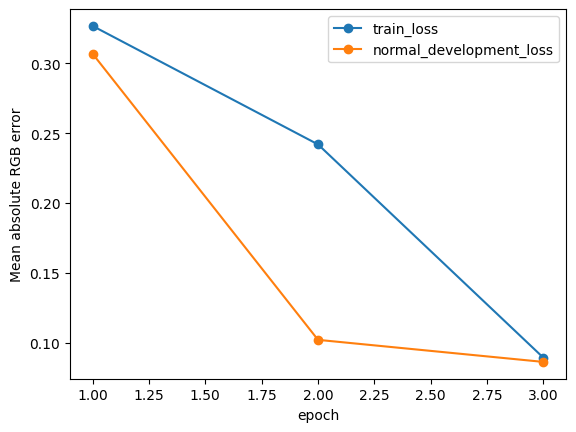

 epoch  train_loss  normal_development_loss  train_seconds  elapsed_seconds  peak_allocated_bytes  peak_reserved_bytes
     1    0.326811                 0.306907       2.623668         2.824417             609729536            901775360
     2    0.241931                 0.101965       1.216957         4.102683             609729536            901775360
     3    0.089097                 0.086153       1.207976         5.362125             609729536            901775360
Mean GPU training seconds per epoch: 1.6828667999998288
Peak allocated GiB: 0.5678548812866211
Illustrative 45-model, 20-epoch training seconds (before category-size adjustment): 1514.580119999846


In [5]:
frame = pd.DataFrame(history)
frame.plot(x='epoch', y=['train_loss','normal_development_loss'], marker='o', ylabel='Mean absolute RGB error')
plt.show()
print(frame.to_string(index=False))
print('Mean GPU training seconds per epoch:', frame.train_seconds.mean())
print('Peak allocated GiB:', frame.peak_allocated_bytes.max()/2**30)
print('Illustrative 45-model, 20-epoch training seconds (before category-size adjustment):',
      frame.train_seconds.mean()*45*20)


## Pilot reconstruction panels (local only)
First three development images in manifest order; no favorable image selection.
Display scales are fixed to [0,1]. These panels remain local under the dataset
retention policy; the public notebook retains the measured curves and tables.

In [6]:
with torch.inference_mode():
    originals = dev[:3].float()/255
    reconstructions = model(originals)
    absolute = anomaly_map(originals, reconstructions, 'absolute')
    squared = anomaly_map(originals, reconstructions, 'squared')
fig, axes = plt.subplots(3,4,figsize=(12,8))
for i in range(3):
    for j, values in enumerate([originals, reconstructions, absolute, squared]):
        a = values[i].cpu().numpy()
        axes[i,j].imshow(a.transpose(1,2,0) if a.ndim==3 else a, vmin=0,vmax=1)
        axes[i,j].axis('off')
for ax,title in zip(axes[0],['Normal original','Reconstruction','Absolute residual','Squared residual']): ax.set_title(title)
plt.tight_layout()
plt.show()


## Pending research and limits
The pilot does not measure detection or localization quality. Its three epochs
cannot establish convergence. A later append-only interpretation will use these
measured curves to set a bounded development epoch budget. Before final training,
publish an estimate adjusted for all category fitting counts, selected epoch count,
three seeds and measured memory. No all-category training has begun.

Development must compare the declared architectures, bottleneck capacities and
losses, plus absolute versus squared maps on fixed fitting-derived synthetic
probes and normal development evidence. Final policy, epochs, seeds, map and
aggregation must then be frozen before calibration/test evaluation. Image thresholds
will use the shared higher empirical 95th percentile of reserved normal scores,
with alarm strictly above threshold; pixel calibration needs its own rule.

All-category metrics, calibration counts/uncertainty, failure analysis and exact
stored Basic CNN comparisons are pending. No claim of improvement is made.
Experiment records: [append-only registry](../experiments/); pilot curves and
resource evidence: [reports](../reports/autoencoder/).


# Continued chronology — bounded development and frozen confirmation

The preceding pilot cells were executed live in the initial notebook kernel.
The following cells execute analysis of retained artifacts from separately run
training/evaluation jobs. **They do not replay training as if it ran live here.**
Training/evaluation source, configs, all curves, failures and provenance are
included below. Raw panels remain local. The initial 'pending' text records the
state at that chronological point; final coverage below supersedes it.


In [1]:
from pathlib import Path
import sys,json,inspect
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
import numpy as np,pandas as pd,matplotlib.pyplot as plt,torch
from PIL import Image
from anomaly_detection.data import CATEGORIES,TEXTURES,autodiscover_data_root,sha256
from anomaly_detection.cnn_research import read_partition,load_resized
from anomaly_detection.ae_research import fit,reconstruct
from anomaly_detection.ae_evaluation import load_checkpoint,calibrate_model,evaluate_frozen,benchmark_model
from anomaly_detection.autoencoder import anomaly_map,image_scores
from anomaly_detection.metrics import binary_metrics,calibrate_normal
from anomaly_detection.pixel_metrics import exact_pixel_metrics
torch.set_num_threads(4)
report=ROOT/'reports/autoencoder'
freeze=json.loads((ROOT/'configs/autoencoder_frozen.json').read_text())
summary=json.loads((report/'summary.json').read_text())
display(pd.read_csv(report/'development_macro.csv'))


Matplotlib is building the font cache; this may take a moment.


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


,variant,map_kind,objective,parameters,training_seconds,peak_allocated_bytes,auroc,ap,recall,fpr,precision,f1,pixel_ap
0,mse,squared,0.368952,31499.0,27.807882,694696448.0,0.614973,0.664527,0.231957,0.062624,0.748295,0.342435,0.122931
1,deeper,squared,0.362364,126667.0,31.906522,704165888.0,0.618811,0.667541,0.187078,0.029506,0.840278,0.292030,0.105916
2,narrow,squared,0.354444,29381.0,26.619081,679926784.0,0.603900,0.652459,0.221972,0.062624,0.764268,0.338984,0.104989
3,mse,absolute,0.349398,31499.0,27.807882,694696448.0,0.595761,0.640488,0.197910,0.062624,0.715625,0.290900,0.103035
4,deeper,absolute,0.339099,126667.0,31.906522,704165888.0,0.591104,0.626092,0.168870,0.046191,0.522321,0.238475,0.087093
5,narrow,absolute,0.339048,29381.0,26.619081,679926784.0,0.590890,0.624026,0.183687,0.062624,0.694196,0.269030,0.087206
6,wide,squared,0.336972,39971.0,28.397048,690227200.0,0.583452,0.632407,0.163213,0.054003,0.716766,0.262525,0.090492
7,base,squared,0.333195,31499.0,33.409697,682064896.0,0.576778,0.623153,0.125117,0.036762,0.783730,0.210669,0.089613
8,wide,absolute,0.316864,39971.0,28.397048,690227200.0,0.562488,0.609130,0.142794,0.062624,0.666667,0.224439,0.071240
9,base,absolute,0.308655,31499.0,33.409697,682064896.0,0.547404,0.589464,0.098882,0.036762,0.741667,0.173945,0.069906


## Bounded training implementation

The source below is the actual loop used for the 20 development fits and 45 final
fits. It trains on unmodified normal fitting images, monitors normal development
loss, records every epoch, and reserves immutable start/result/failure events.
Development excludes an inner fitting holdout from gradients and generates fixed
synthetic probes from that holdout only. Final fits use every fitting normal,
with no calibration/test gradient access. All variants ran exactly 20 epochs;
there is no best-test-epoch selection. The held-out probes are proxies, not
industrial defects. Full optimizer/RNG state is retained locally.

Chronology disclosure: the scalar selection rule was documented after the first
base bottle development result existed, while the remaining jobs were running.
Categories and five ablations were fixed before development. The final policy
was frozen before final fits; no official autoencoder test results informed it.


In [2]:
"""Normal-only AE fits, with immutable experiment events and full learning curves."""
import copy
import json
import time
import traceback
from pathlib import Path
import torch
import pandas as pd
from sklearn.metrics import average_precision_score
from anomaly_detection.autoencoder import ConvAutoencoder, reconstruction_loss, anomaly_map, image_scores
from anomaly_detection.basic_cnn import seed_everything
from anomaly_detection.cnn_research import ROOT, read_partition, require_fitting, load_resized, inner_fit_split, make_probes
from anomaly_detection.data import sha256
from anomaly_detection.tracking import record, config_hash
from anomaly_detection.metrics import binary_metrics, calibrate_normal


@torch.inference_mode()
def reconstruct(model, images, batch_size=16):
    model.eval()
    return torch.cat([model(b.float()/255).cpu() for b in images.split(batch_size)])


def fit(identifier, category, config, final=False):
    compact = ROOT/'reports/autoencoder/runs'
    compact.mkdir(parents=True, exist_ok=True)
    local = ROOT/'outputs/autoencoder'/identifier
    local.mkdir(parents=True, exist_ok=False)
    checkpoint = ROOT/'checkpoints/autoencoder'/identifier/'last.pt'
    checkpoint.parent.mkdir(parents=True, exist_ok=False)
    entry = dict(experiment_id=identifier+'-start',model_family='ConvAutoencoder',categories=[category],
        hypothesis='Controlled normal-only reconstruction ablation' if not final else 'Frozen category-specific confirmation',
        preprocessing='PIL RGB bilinear, /255 float32', hyperparameters=config, seed=config['seed'],
        environment=dict(torch=torch.__version__,gpu=torch.cuda.get_device_name(0),
            source_sha256={p:sha256(ROOT/p) for p in ['src/anomaly_detection/autoencoder.py','src/anomaly_detection/ae_research.py']},
            partitions=json.loads((ROOT/'reports/dataset_validation.json').read_text())['partitions'],
            lock_sha256=sha256(ROOT/'requirements.lock.txt')),
        training=dict(final=final),metrics={},calibration={},paths=dict(local=str(local.relative_to(ROOT))),
        interpretation='No calibration or official test access',decision='retain all epochs',status='started')
    record(ROOT/'experiments',entry)
    started=time.perf_counter()
    try:
        seed_everything(config['seed'])
        rows=read_partition('fit',category)
        require_fitting(rows)
        # Same fitting-derived held-out probes across variants; excluded from gradients during development.
        learning,probe_rows=(rows,None) if final else inner_fit_split(rows)
        images=load_resized(learning,config['resolution']).cuda()
        dev=load_resized(read_partition('development',category),config['resolution']).cuda()
        if not final:
            probe_images=load_resized(probe_rows,config['resolution']).cuda()
            probes,masks=make_probes(probe_images,probe_rows)
        model=ConvAutoencoder(**{k:config[k] for k in ['width','depth','latent_channels']}).cuda()
        optimizer=torch.optim.Adam(model.parameters(),lr=config['learning_rate'])
        shuffle=torch.Generator().manual_seed(config['seed'])
        torch.cuda.synchronize();torch.cuda.reset_peak_memory_stats()
        history=[]
        for epoch in range(1,config['epochs']+1):
            tick=time.perf_counter();model.train();total=0.
            for indices in torch.randperm(len(images),generator=shuffle).split(config['batch_size']):
                batch=images[indices.cuda()].float()/255
                optimizer.zero_grad(set_to_none=True)
                loss=reconstruction_loss(model(batch),batch,config['loss'])
                if not torch.isfinite(loss):raise RuntimeError('Nonfinite reconstruction loss')
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),10.,error_if_nonfinite=True)
                optimizer.step();total+=loss.item()*len(batch)
            torch.cuda.synchronize()
            train_seconds=time.perf_counter()-tick
            predicted=reconstruct(model,dev,config['batch_size'])
            dev_loss=reconstruction_loss(predicted,dev.cpu().float()/255,config['loss']).item()
            row=dict(epoch=epoch,train_loss=total/len(images),normal_development_loss=dev_loss,train_seconds=train_seconds,
                peak_allocated_bytes=torch.cuda.max_memory_allocated(),peak_reserved_bytes=torch.cuda.max_memory_reserved())
            history.append(row)
            pd.DataFrame(history).to_csv(compact/(identifier+'-history.csv'),index=False)
            if row['peak_allocated_bytes']>6*2**30 or time.perf_counter()-started>1200:
                raise RuntimeError('Per-run memory/time budget exceeded')
        torch.save(dict(state_dict=model.state_dict(),config=config,category=category,training_phase='final' if final else 'development'),checkpoint)
        torch.save(dict(optimizer=optimizer.state_dict(),shuffle_rng=shuffle.get_state(),torch_rng=torch.get_rng_state(),cuda_rng=torch.cuda.get_rng_state()),checkpoint.parent/'training-state.pt')
        metrics={}
        if not final:
            with torch.inference_mode():
                recon=torch.cat([model(b).cpu() for b in probes.split(config['batch_size'])])
            for kind in ['absolute','squared']:
                maps=anomaly_map(probes.cpu(),recon,kind)
                normal_maps=anomaly_map(dev.cpu().float()/255,predicted,kind)
                scores=image_scores(maps).numpy()
                labels=masks.cpu().flatten(1).any(1).numpy().astype(int)
                values=binary_metrics(labels,scores,calibrate_normal(image_scores(normal_maps).numpy()))
                values['pixel_ap']=float(average_precision_score(masks.cpu().numpy().ravel(),maps.numpy().ravel()))
                metrics[kind]=values
            torch.save(dict(original=dev[:3].cpu(),reconstruction=predicted[:3]),local/'development-reconstructions.pt')
        result=dict(experiment_id=identifier,category=category,configuration=config,configuration_sha256=config_hash(config),
            gradient_normal_images=len(learning),probe_normal_sources=0 if final else len(probe_rows),
            parameters=sum(p.numel() for p in model.parameters()),metrics=metrics,history=history,
            training_seconds_including_loading_validation=time.perf_counter()-started,
            peak_allocated_bytes=torch.cuda.max_memory_allocated(),peak_reserved_bytes=torch.cuda.max_memory_reserved(),
            checkpoint=str(checkpoint.relative_to(ROOT)),checkpoint_sha256=sha256(checkpoint),checkpoint_bytes=checkpoint.stat().st_size)
        with (compact/(identifier+'-result.json')).open('x') as stream:json.dump(result,stream,indent=2)
        event=copy.deepcopy(entry)
        event.update(experiment_id=identifier+'-result',status='completed',metrics=result,decision='await development comparison' if not final else 'frozen fit complete')
        record(ROOT/'experiments',event)
        print(identifier, 'completed',round(result['training_seconds_including_loading_validation'],2),metrics,flush=True)
        return result
    except BaseException as exc:
        (local/'failure.txt').write_text(traceback.format_exc())
        event=copy.deepcopy(entry)
        event.update(experiment_id=identifier+'-failure',status='failed',interpretation=str(exc),decision='preserve failure')
        record(ROOT/'experiments',event)
        raise


## Hypotheses, configurations and complete development ledger

Depth 4 tests greater context/compression; latent 2 tests stricter capacity and
latent 32 tests whether extra capacity helps normal reconstruction at the cost
of reconstructing edited regions. MSE tests emphasis on large residuals against
L1. Only one factor changes from the shallow base. A fixed four-category mean of
(proxy image AUROC + pixel AP)/2 chooses variant/map, with recall then parameter
count as tie breakers. Both absolute and squared maps are reported for every fit.
Raw L1 and MSE values have different units and are not ranked against each other.


In [3]:
development=pd.read_csv(report/'development_comparison.csv')
display(development)
events=[json.loads(p.read_text()) for p in sorted((ROOT/'experiments').glob('02-*.json'))]
display(pd.DataFrame([dict(experiment=e['experiment_id'],**e['hyperparameters']) for e in events
                      if e['experiment_id'].startswith('02-dev-') and e['status']=='started']))
shapes=[]
for variant in ['base','deeper','narrow','wide','mse']:
    event=next(e for e in events if e['experiment_id']==f'02-dev-{variant}-bottle-s2026-v1-start')
    c=event['hyperparameters']
    architecture=ConvAutoencoder(**{k:c[k] for k in ['width','depth','latent_channels']})
    with torch.inference_mode():
        x=torch.zeros(1,3,256,256)
        encoded=architecture.encoder(x);z=architecture.bottleneck(encoded);y=architecture.decoder(z)
    shapes.append(dict(variant=variant,input=list(x.shape),encoded=list(encoded.shape),
        bottleneck=list(z.shape),output=list(y.shape),parameters=sum(p.numel() for p in architecture.parameters()),
        scalar_compression=x.numel()/z.numel()))
display(pd.DataFrame(shapes))
print('Depth 4 also reduces bottleneck spatial area fourfold; this ablation does not isolate depth from compression.')
recomputed=development.groupby(['variant','map_kind']).objective.mean().sort_values(ascending=False)
print('Recomputed selection objective:',recomputed.to_string())
assert recomputed.index[0]==(freeze['selected_variant'],freeze['configuration']['map_kind'])
display(pd.DataFrame([dict(id=e['experiment_id'],status=e['status'],hypothesis=e['hypothesis'],decision=e['decision']) for e in events]))
failures=[e for e in events if e['status']=='failed']
print('Failed trials:',len(failures))
for e in failures: print(e['experiment_id'],e['interpretation'])


,variant,category,map_kind,objective,parameters,training_seconds,peak_allocated_bytes,auroc,ap,recall,fpr,precision,f1,pixel_ap
0,base,bottle,absolute,0.378648,31499,30.313404,669793280,0.643282,0.685237,0.103448,0.000000,1.000000,0.187500,0.114015
1,base,bottle,squared,0.375805,31499,30.313404,669793280,0.634958,0.665239,0.068966,0.000000,1.000000,0.129032,0.116652
2,base,cable,absolute,0.237587,31499,39.095559,676215808,0.424558,0.471515,0.064516,0.064516,0.500000,0.114286,0.050615
3,base,cable,squared,0.245159,31499,39.095559,676215808,0.432882,0.476107,0.064516,0.064516,0.500000,0.114286,0.057436
4,base,carpet,absolute,0.312405,31499,31.497793,703151104,0.570020,0.612779,0.102564,0.051282,0.666667,0.177778,0.054790
5,base,carpet,squared,0.361702,31499,31.497793,703151104,0.634780,0.680718,0.179487,0.051282,0.777778,0.291667,0.088624
6,base,tile,absolute,0.305982,31499,32.732030,679099392,0.551758,0.588324,0.125000,0.031250,0.800000,0.216216,0.060206
7,base,tile,squared,0.350116,31499,32.732030,679099392,0.604492,0.670547,0.187500,0.031250,0.857143,0.307692,0.095739
8,deeper,bottle,absolute,0.506127,126667,28.083723,692041728,0.796671,0.829960,0.482759,0.068966,0.875000,0.622222,0.215584
9,deeper,bottle,squared,0.505310,126667,28.083723,692041728,0.791914,0.824907,0.379310,0.034483,0.916667,0.536585,0.218705


,experiment,width,depth,latent_channels,loss,resolution,batch_size,learning_rate,epochs,seed
0,02-dev-base-bottle-s2026-v1-start,16,3,8,l1,256,16,0.001,20,2026
1,02-dev-base-cable-s2026-v1-start,16,3,8,l1,256,16,0.001,20,2026
2,02-dev-base-carpet-s2026-v1-start,16,3,8,l1,256,16,0.001,20,2026
3,02-dev-base-tile-s2026-v1-start,16,3,8,l1,256,16,0.001,20,2026
4,02-dev-deeper-bottle-s2026-v1-start,16,4,8,l1,256,16,0.001,20,2026
5,02-dev-deeper-cable-s2026-v1-start,16,4,8,l1,256,16,0.001,20,2026
6,02-dev-deeper-carpet-s2026-v1-start,16,4,8,l1,256,16,0.001,20,2026
7,02-dev-deeper-tile-s2026-v1-start,16,4,8,l1,256,16,0.001,20,2026
8,02-dev-mse-bottle-s2026-v1-start,16,3,8,mse,256,16,0.001,20,2026
9,02-dev-mse-cable-s2026-v1-start,16,3,8,mse,256,16,0.001,20,2026


,variant,input,encoded,bottleneck,output,parameters,scalar_compression
0,base,"[1, 3, 256, 256]","[1, 64, 32, 32]","[1, 8, 32, 32]","[1, 3, 256, 256]",31499,24.0
1,deeper,"[1, 3, 256, 256]","[1, 128, 16, 16]","[1, 8, 16, 16]","[1, 3, 256, 256]",126667,96.0
2,narrow,"[1, 3, 256, 256]","[1, 64, 32, 32]","[1, 2, 32, 32]","[1, 3, 256, 256]",29381,96.0
3,wide,"[1, 3, 256, 256]","[1, 64, 32, 32]","[1, 32, 32, 32]","[1, 3, 256, 256]",39971,6.0
4,mse,"[1, 3, 256, 256]","[1, 64, 32, 32]","[1, 8, 32, 32]","[1, 3, 256, 256]",31499,24.0


Depth 4 also reduces bottleneck spatial area fourfold; this ablation does not isolate depth from compression.
Recomputed selection objective: variant  map_kind
mse      squared     0.368952
deeper   squared     0.362364
narrow   squared     0.354444
mse      absolute    0.349398
deeper   absolute    0.339099
narrow   absolute    0.339048
wide     squared     0.336972
base     squared     0.333195
wide     absolute    0.316864
base     absolute    0.308655


,id,status,hypothesis,decision
0,02-dev-base-bottle-s2026-v1-decision,completed,"A shallow, capacity-limited reconstruction mod...",reject
1,02-dev-base-bottle-s2026-v1-result,completed,Controlled normal-only reconstruction ablation,await development comparison
2,02-dev-base-bottle-s2026-v1-start,started,Controlled normal-only reconstruction ablation,retain all epochs
3,02-dev-base-cable-s2026-v1-decision,completed,"A shallow, capacity-limited reconstruction mod...",reject
4,02-dev-base-cable-s2026-v1-result,completed,Controlled normal-only reconstruction ablation,await development comparison
...,...,...,...,...
238,02-test-mse-zipper-s2026-v1-start,started,Frozen normal-only reconstruction baseline; no...,frozen evaluation
239,02-test-mse-zipper-s2027-v1-result,completed,Frozen normal-only reconstruction baseline; no...,retain even if disappointing
240,02-test-mse-zipper-s2027-v1-start,started,Frozen normal-only reconstruction baseline; no...,frozen evaluation
241,02-test-mse-zipper-s2028-v1-result,completed,Frozen normal-only reconstruction baseline; no...,retain even if disappointing


Failed trials: 0


## Every development learning curve

Each panel includes all epochs from one variant/category. Training and normal
development use the same reconstruction loss within a panel. Cross-panel loss
magnitudes for MSE versus L1 are not comparable. No curves are omitted based on
their appearance. Fixed epochs bound compute; a low reconstruction loss alone
does not imply useful anomaly detection.
Loss axes are logarithmic to keep late-epoch changes visible.


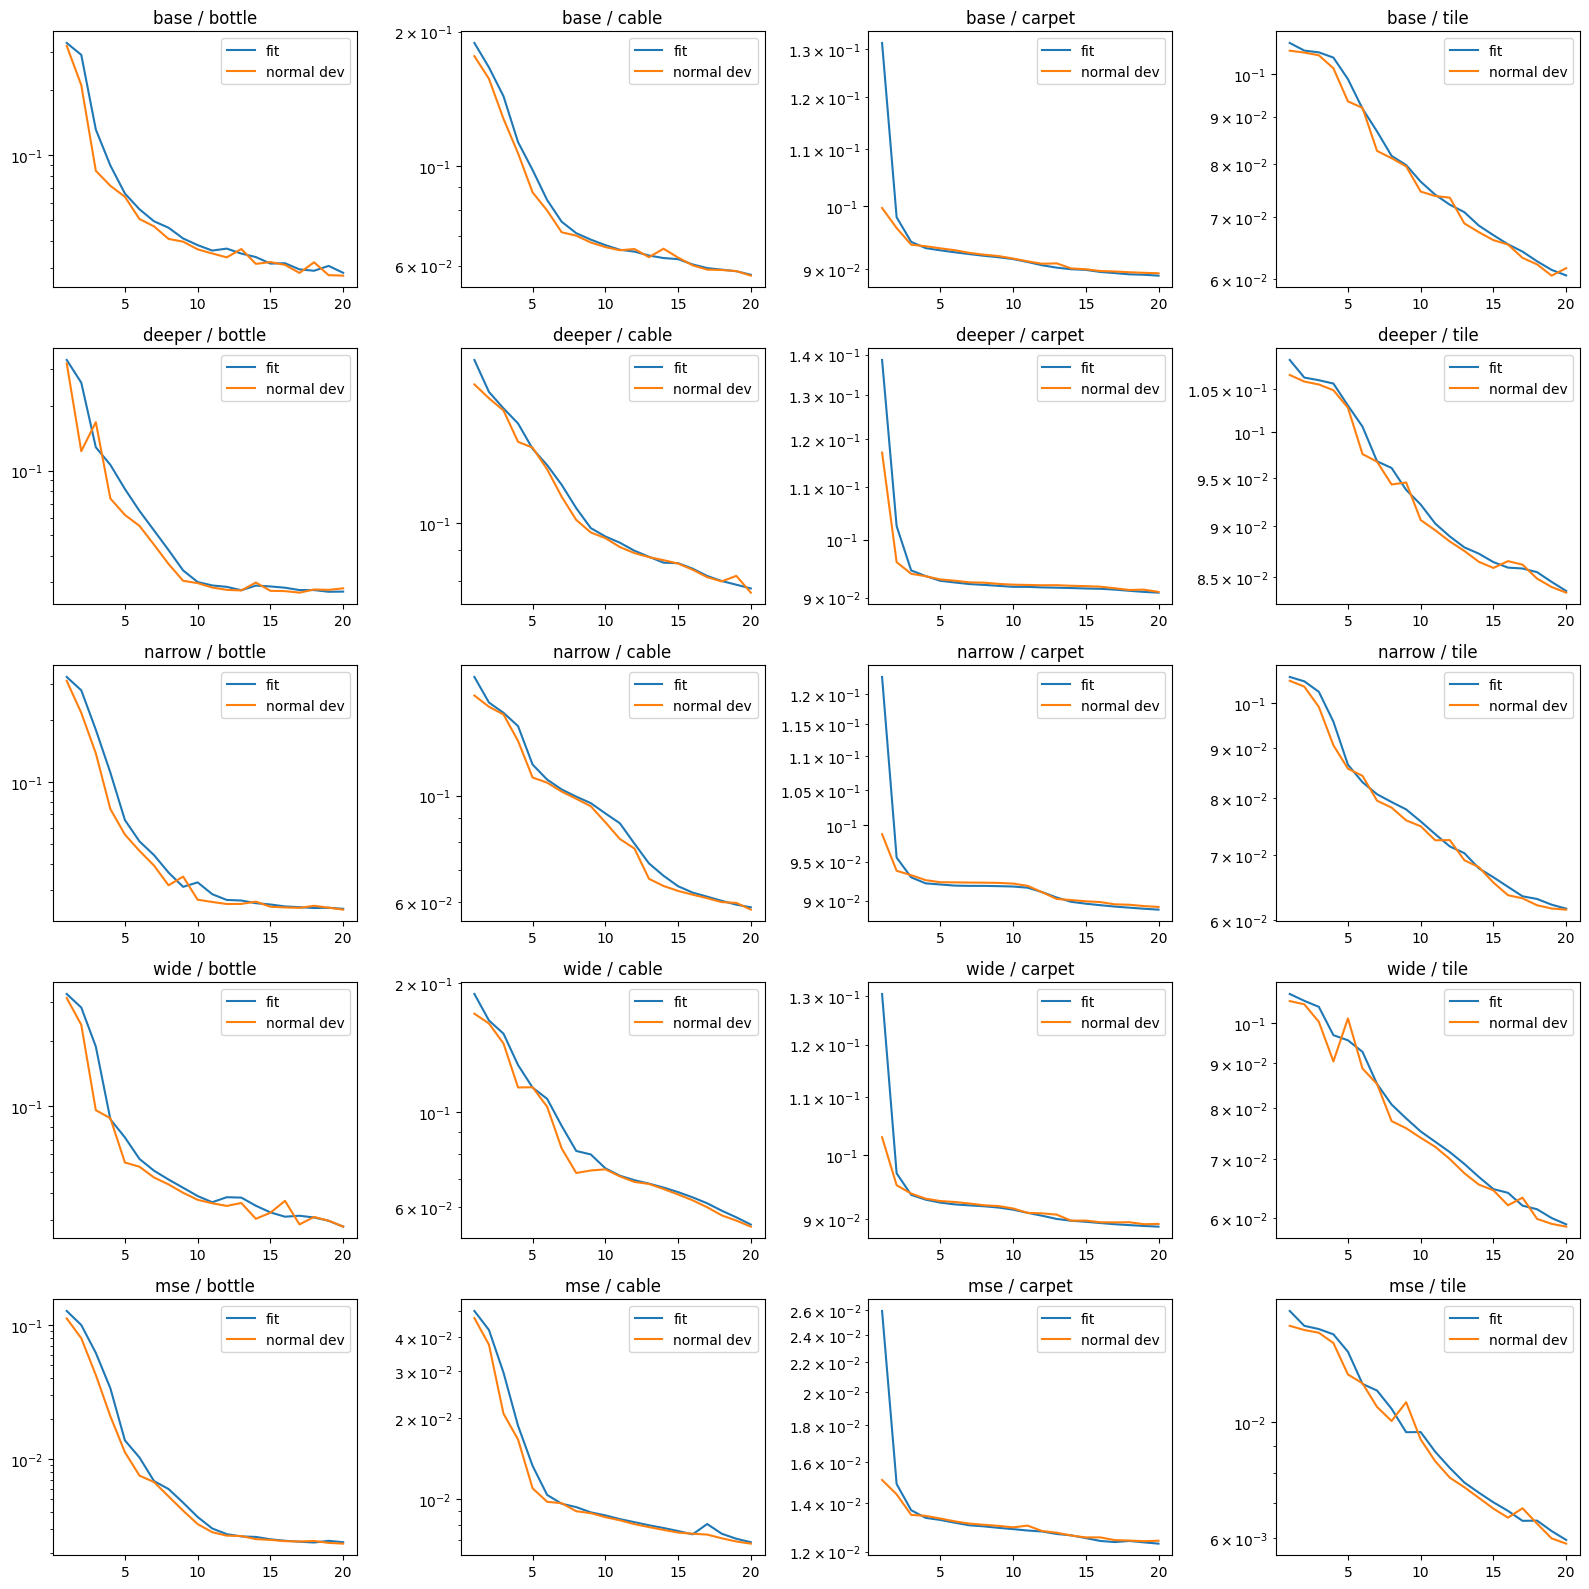

In [4]:
fig,axes=plt.subplots(5,4,figsize=(16,16))
for i,variant in enumerate(['base','deeper','narrow','wide','mse']):
    for j,category in enumerate(['bottle','cable','carpet','tile']):
        h=pd.read_csv(report/f'runs/02-dev-{variant}-{category}-s2026-v1-history.csv')
        axes[i,j].plot(h.epoch,h.train_loss,label='fit')
        axes[i,j].plot(h.epoch,h.normal_development_loss,label='normal dev')
        axes[i,j].set_title(variant+' / '+category);axes[i,j].legend();axes[i,j].set_yscale('log')
plt.tight_layout();plt.show()


## Reconstruction examples for every development variant (local)

The first normal development image in manifest order is shown for every one of
the 20 development fits. These retained tensors come from the original fits,
not a new training run or favorable example search. Columns are original,
reconstruction, absolute residual (fixed [0,.2]) and squared residual (fixed
[0,.05]). Rows follow base, deeper, narrow, wide, MSE. Licensed panels stay local.


In [5]:
development_panels=[]
for category in ['bottle','cable','carpet','tile']:
    fig,axes=plt.subplots(5,4,figsize=(12,13))
    for i,variant in enumerate(['base','deeper','narrow','wide','mse']):
        saved=torch.load(ROOT/f'outputs/autoencoder/02-dev-{variant}-{category}-s2026-v1/development-reconstructions.pt',weights_only=True)
        x=saved['original'][:1].float()/255
        y=saved['reconstruction'][:1]
        values=[x[0].permute(1,2,0).numpy(),y[0].permute(1,2,0).numpy(),
                anomaly_map(x,y,'absolute')[0].numpy(),anomaly_map(x,y,'squared')[0].numpy()]
        for j,a in enumerate(values):
            axes[i,j].imshow(a,vmin=0,vmax=(.2 if j==2 else (.05 if j==3 else 1)))
            axes[i,j].axis('off')
        axes[i,0].set_title(category+' / '+variant)
    plt.tight_layout();plt.show()


## Measured ablation interpretations

Both maps for every category/configuration are reported above. The following
compact table shows each variant’s higher-scoring map on the fixed proxy objective.
It does not select a separate map per category.

| Variant | Map | Proxy image AUROC | Proxy pixel AP | Objective | Parameters |
|---|---|---:|---:|---:|---:|
| base | squared | 0.576778 | 0.089613 | 0.333195 | 31,499 |
| deeper | squared | 0.618811 | 0.105916 | 0.362364 | 126,667 |
| narrow | squared | 0.603900 | 0.104989 | 0.354444 | 29,381 |
| wide | squared | 0.583452 | 0.090492 | 0.336972 | 39,971 |
| mse | squared | 0.614973 | 0.122931 | 0.368952 | 31,499 |

The deeper model raised the proxy objective by 0.029168 over base,
but depth also reduced latent spatial area fourfold and increased parameter count.
This trial cannot separate context, compression and parameter-count effects.

The narrow bottleneck raised the objective by 0.021249;
the wide bottleneck changed it by 0.003776.
More capacity did not establish a compelling advantage on this proxy.

MSE/squared residuals ranked first, only 0.006588 above the runner-up.
The four-category, single-development-seed comparison does not establish a
statistically certain architecture ranking. The frozen rule still selects
one policy for confirmation; rejected trials remain visible. No specific
combined-loss or smoothing hypothesis was supported strongly enough to expand
this initial bounded study. Real-defect transfer remains a separate question.

## Development decision and measured compute gate

The following freeze and budget were written before all-category training and
official test evaluation. The fixed proxy rule determines selection; real test
results cannot revise it. There was no evidence-based need to add a combined
loss, smoothing or resolution grid in this initial bounded baseline. Their
absence is not a claim that they would fail. Fixed 256-square inputs can erase
small details and distort aspect ratios, a limitation retained in the benchmark.


In [6]:
print(json.dumps(freeze,indent=2))
print(json.dumps(json.loads((report/'compute_budget.json').read_text()),indent=2))
selected=pd.read_csv(report/'development_macro.csv').iloc[0]
print('Selected using proxy objective:',selected.variant,selected.map_kind,selected.objective)
print('Proxy advantage is not a real-defect performance guarantee.')


{
  "frozen_at_utc": "2026-11-12T15:51:26.741536+00:00",
  "selected_variant": "mse",
  "configuration": {
    "width": 16,
    "depth": 3,
    "latent_channels": 8,
    "loss": "mse",
    "resolution": 256,
    "batch_size": 16,
    "learning_rate": 0.001,
    "epochs": 20,
    "seed": 2026,
    "map_kind": "squared"
  },
  "categories": [
    "bottle",
    "cable",
    "capsule",
    "carpet",
    "grid",
    "hazelnut",
    "leather",
    "metal_nut",
    "pill",
    "screw",
    "tile",
    "toothbrush",
    "transistor",
    "wood",
    "zipper"
  ],
  "seeds": [
    2026,
    2027,
    2028
  ],
  "scoring": "channel-mean residual, fixed top ceil(1% HW) mean at model resolution; native bilinear pixel maps",
  "calibration": "image higher q95, strict >; pixel upper bin edge pooled normal q99.5 at model resolution, 65536 bins",
  "evaluation_source_sha256": "4d5cfd2505fdbc7b3b77fff317bd43a8937acc545d4802eb9e0494f006b3b8ed",
  "pixel_metric_source_sha256": "384dd283421560f7d44618ca1

## Threshold calibration and uncertainty

The API below accepts only a category's reserved normal calibration partition.
It takes no official test scores, labels or masks. Image alarms use the shared
higher empirical 95th percentile and strict > comparison, target FPR 5%.
Localization uses a separately calibrated pooled normal-pixel q99.5, rounded
up to a 65,536-bin boundary. Image and pixel thresholds are not interchangeable.
Bootstrap intervals resample whole normal images for the image threshold.
Small calibration counts and distribution shift prevent a population guarantee.


In [7]:
def calibrate_model(model, category, resolution, seed=2026):
    """Only the calibration manifest is read; API takes no test labels/masks."""
    rows = read_partition("calibration", category)
    images = load_resized(rows, resolution).cuda()
    maps = anomaly_map(images.cpu().float()/255, reconstruct(model, images), model.map_kind)
    scores = image_scores(maps).numpy()
    primary, secondary = calibrate_normal(scores), calibrate_normal(scores, .01)
    # Conservative upper edge for the fixed quantile's bin.
    probabilities = maps.numpy().ravel()
    bins = 65536
    histogram = np.bincount(np.minimum((probabilities*bins).astype(np.int64), bins-1), minlength=bins)
    rank = int(np.ceil(.995*(len(probabilities)-1))) + 1
    index = int(np.searchsorted(np.cumsum(histogram), rank))
    pixel_threshold = min(1., (index+1)/bins)
    rng = np.random.default_rng(seed)
    draws = rng.choice(scores, size=(2000,len(scores)), replace=True)
    boot_thresholds = np.quantile(draws,.95,axis=1,method="higher")
    return {"category": category, "images": len(rows), "image_threshold": primary,
            "secondary_image_threshold_q99": secondary, "pixel_threshold": pixel_threshold,
            "image_quantile": .95, "pixel_quantile": .995, "pixel_bins": bins,
            "pixel_calibration_samples": len(probabilities), "pixel_score_resolution": resolution,
            "image_threshold_bootstrap_95ci": np.quantile(boot_thresholds,[.025,.975]).tolist(),
            "calibration_scores": scores.tolist(),
            "method": "normal calibration only; higher order statistic; strict score > threshold",
            "source_paths_sha256": config_hash(rows[["path","sha256"]].to_dict("records"))}

## Native-resolution metrics and measured inference

The evaluator freezes checkpoint/configuration identities, writes calibration
before reading official test rows, then restores continuous maps by bilinear
interpolation to native resolution. Ground-truth masks are never interpolated
for primary metrics. Exact native pixel AUROC/AP/AU-PRO use the same shared
implementation as Notebook 01. AU-PRO weights 8-connected regions equally and
integrates background FPR through 0.30. Image scores remain at model resolution.
The implementation and latency scope are printed for review. Each latency run
uses 50 warmups and 200 synchronized timed batch-one iterations; disk decode
is excluded. Residual-map construction is included in the model stage.
Inference allocation also includes the evaluator's resident test-image cache,
as in Notebook 01; it is not an isolated deployment-process memory estimate.


In [8]:
__file__ = str(ROOT/'src/anomaly_detection/ae_evaluation.py')
"""Frozen calibration, one-shot official evaluation and native pixel metrics."""
from pathlib import Path
from datetime import datetime, timezone
import gc
import json
import time
import traceback
import subprocess

import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import label
import torch
from torch.nn import functional as F

from anomaly_detection.autoencoder import ConvAutoencoder, anomaly_map, image_scores
from anomaly_detection.cnn_research import ROOT, read_partition, load_resized
from anomaly_detection.ae_research import reconstruct
from anomaly_detection.data import CATEGORIES, autodiscover_data_root, sha256
from anomaly_detection.metrics import binary_metrics, calibrate_normal
from anomaly_detection.pixel_metrics import exact_pixel_metrics, histogram_metrics
from anomaly_detection.tracking import config_hash, record


def load_checkpoint(path):
    saved = torch.load(path, map_location="cpu", weights_only=True)
    model = ConvAutoencoder(**{k:saved["config"][k] for k in ["width","depth","latent_channels"]})
    model.load_state_dict(saved["state_dict"])
    model = model.cuda().eval()
    model.map_kind = saved["config"]["map_kind"]
    return model, saved


def calibrate_model(model, category, resolution, seed=2026):
    """Only the calibration manifest is read; API takes no test labels/masks."""
    rows = read_partition("calibration", category)
    images = load_resized(rows, resolution).cuda()
    maps = anomaly_map(images.cpu().float()/255, reconstruct(model, images), model.map_kind)
    scores = image_scores(maps).numpy()
    primary, secondary = calibrate_normal(scores), calibrate_normal(scores, .01)
    # Conservative upper edge for the fixed quantile's bin.
    probabilities = maps.numpy().ravel()
    bins = 65536
    histogram = np.bincount(np.minimum((probabilities*bins).astype(np.int64), bins-1), minlength=bins)
    rank = int(np.ceil(.995*(len(probabilities)-1))) + 1
    index = int(np.searchsorted(np.cumsum(histogram), rank))
    pixel_threshold = min(1., (index+1)/bins)
    rng = np.random.default_rng(seed)
    draws = rng.choice(scores, size=(2000,len(scores)), replace=True)
    boot_thresholds = np.quantile(draws,.95,axis=1,method="higher")
    return {"category": category, "images": len(rows), "image_threshold": primary,
            "secondary_image_threshold_q99": secondary, "pixel_threshold": pixel_threshold,
            "image_quantile": .95, "pixel_quantile": .995, "pixel_bins": bins,
            "pixel_calibration_samples": len(probabilities), "pixel_score_resolution": resolution,
            "image_threshold_bootstrap_95ci": np.quantile(boot_thresholds,[.025,.975]).tolist(),
            "calibration_scores": scores.tolist(),
            "method": "normal calibration only; higher order statistic; strict score > threshold",
            "source_paths_sha256": config_hash(rows[["path","sha256"]].to_dict("records"))}


@torch.inference_mode()
def benchmark_model(model, calibration_path, resolution, native_shape, output):
    """Memory-resident RGB input; disk decode excluded and explicitly disclosed."""
    root = autodiscover_data_root(ROOT)
    with Image.open(root / calibration_path) as image:
        raw = image.convert("RGB").copy()
    def once():
        start = time.perf_counter()
        array = np.asarray(raw.resize((resolution,resolution), Image.Resampling.BILINEAR)).copy()
        x = torch.from_numpy(array).permute(2,0,1).unsqueeze(0).float()/255
        pre = time.perf_counter()
        x = x.cuda(); torch.cuda.synchronize()
        transfer = time.perf_counter()
        reconstruction = model(x)
        maps = anomaly_map(x, reconstruction, model.map_kind).unsqueeze(1); torch.cuda.synchronize()
        forward = time.perf_counter()
        native = F.interpolate(maps, size=native_shape, mode="bilinear", align_corners=False)
        result = native.cpu().numpy()
        float(image_scores(maps[:,0]).item())
        torch.cuda.synchronize()
        finish = time.perf_counter()
        return np.array([pre-start,transfer-pre,forward-transfer,finish-forward,finish-start])*1000
    for _ in range(50): once()
    torch.cuda.reset_peak_memory_stats()
    times = np.stack([once() for _ in range(200)])
    names = ["preprocessing", "host_to_device", "model", "postprocessing", "end_to_end"]
    pd.DataFrame(times,columns=names).to_csv(output,index=False,lineterminator="\n")
    power_context={}
    for key,command in (("windows_scheme",["powercfg","/getactivescheme"]),
                        ("gpu",["nvidia-smi","--query-gpu=name,driver_version,power.limit,pstate,clocks.gr,temperature.gpu","--format=csv,noheader"])):
        try:
            process=subprocess.run(command,capture_output=True,text=True,timeout=10,check=True)
            power_context[key]=process.stdout.strip()
        except (OSError,subprocess.SubprocessError) as exc:power_context[key]=str(exc)
    return {name: {"p50_ms":float(np.median(times[:,i])),"p95_ms":float(np.quantile(times[:,i],.95))}
            for i,name in enumerate(names)} | {
                "warmup":50,"iterations":200,"batch_size":1,"precision":"float32",
                "scope":"memory-resident RGB -> native residual map on CPU; file read/decode excluded",
                "power_context_at_end_of_timing":power_context,
                "peak_inference_allocated_bytes":torch.cuda.max_memory_allocated(),
                "peak_inference_reserved_bytes":torch.cuda.max_memory_reserved()}


def image_bootstrap(labels, scores, threshold, weights):
    """Whole-image resampling, exact weighted score ties; no threshold refitting."""
    order=np.argsort(scores,kind="stable")[::-1]
    values=np.asarray(scores)[order]
    y=np.asarray(labels)[order]
    w=weights[:,order]
    endpoints=np.r_[np.flatnonzero(values[1:] != values[:-1]),len(values)-1]
    tp=np.cumsum(w*y,axis=1)[:,endpoints]
    fp=np.cumsum(w*(1-y),axis=1)[:,endpoints]
    total_p,total_n=tp[:,-1],fp[:,-1]
    valid=(total_p>0)&(total_n>0)
    tp,fp=tp[valid],fp[valid]
    total_p,total_n=total_p[valid],total_n[valid]
    recall=tp/total_p[:,None]; fpr=fp/total_n[:,None]
    roc=np.trapezoid(np.c_[np.zeros(len(tp)),recall],np.c_[np.zeros(len(tp)),fpr],axis=1)
    increments=np.diff(np.c_[np.zeros(len(tp)),tp],axis=1)
    precision=np.divide(tp,tp+fp,out=np.zeros_like(tp,dtype=float),where=tp+fp>0)
    ap=(increments/total_p[:,None]*precision).sum(1)
    predictions=(np.asarray(scores)>threshold).astype(int)
    true_p=(weights*(np.asarray(labels)*predictions)).sum(1)[valid]
    false_p=(weights*((1-np.asarray(labels))*predictions)).sum(1)[valid]
    rec=true_p/total_p; false_rate=false_p/total_n
    prec=np.divide(true_p,true_p+false_p,out=np.zeros_like(true_p,dtype=float),where=true_p+false_p>0)
    f1=np.divide(2*prec*rec,prec+rec,out=np.zeros_like(rec),where=prec+rec>0)
    return {"image_auroc":roc,"image_ap":ap,"recall":rec,"fpr":false_rate,"precision":prec,"f1":f1},valid


def bootstrap_evaluation(labels, scores, threshold, positive_hist, negative_hist, region_hist, region_counts, category):
    # Same resamples for all model seeds within a category preserve dependence
    # when averaging seed results; category draws are independent.
    rng=np.random.default_rng(2026+CATEGORIES.index(category))
    n=len(labels)
    weights=rng.multinomial(n,np.full(n,1/n),size=2000)
    vectors,valid=image_bootstrap(labels,scores,threshold,weights)
    from threadpoolctl import threadpool_limits
    with threadpool_limits(limits=4):
        pos=weights[valid]@positive_hist.astype(np.float64)
        neg=weights[valid]@negative_hist.astype(np.float64)
        region=weights[valid]@region_hist.astype(np.float64)
    counts=weights[valid]@np.asarray(region_counts)
    pixel=np.array([histogram_metrics(p,n,r,c) for p,n,r,c in zip(pos,neg,region,counts)])
    vectors.update(pixel_auroc=pixel[:,0],pixel_ap=pixel[:,1],au_pro=pixel[:,2])
    intervals={name:np.quantile(v,[.025,.975]).tolist() for name,v in vectors.items()}
    return {"replicates":2000,"invalid_single_class_replicates":int((~valid).sum()),
            "95ci":intervals,"pixel_ci_method":"whole-image bootstrap, 4096 fixed [0,1] residual bins; primary metrics exact"},vectors


def evaluate_frozen(identifier, training_result, freeze_sha256):
    """One immutable evaluation reservation per category/seed; never retries itself."""
    from anomaly_detection.cnn_research import code_identity
    freeze_path=ROOT/"configs/autoencoder_frozen.json"
    if sha256(freeze_path)!=freeze_sha256:raise ValueError("Frozen confirmation identity mismatch")
    frozen=json.loads(freeze_path.read_text())
    for path, expected_hash in frozen["source_sha256"].items():
        if sha256(ROOT/path)!=expected_hash:raise ValueError("Frozen model/training source changed")
    expected=dict(frozen["configuration"],seed=training_result["configuration"]["seed"])
    if expected!=training_result["configuration"] or expected["seed"] not in frozen["seeds"]:
        raise ValueError("Training configuration differs from frozen policy")
    if training_result["category"] not in frozen["categories"]:
        raise ValueError("Unregistered category")
    if sha256(Path(__file__))!=frozen["evaluation_source_sha256"]:
        raise ValueError("Evaluation implementation changed after freeze")
    if sha256(Path(__file__).with_name("pixel_metrics.py"))!=frozen["pixel_metric_source_sha256"]:
        raise ValueError("Pixel metric implementation changed after freeze")
    result_dir=ROOT/"reports/autoencoder/evaluation"
    result_dir.mkdir(parents=True,exist_ok=True)
    local=ROOT/"outputs/autoencoder"/identifier
    local.mkdir(parents=True,exist_ok=False)
    category=training_result["category"]
    config=training_result["configuration"]
    entry={"experiment_id":identifier+"-start","model_family":"ConvAutoencoder","categories":[category],
           "hypothesis":"Frozen normal-only reconstruction baseline; no further selection",
           "preprocessing":{"resolution":config["resolution"],"native_map":"bilinear, align_corners=False"},
           "hyperparameters":config,"seed":config["seed"],
           "environment":json.loads((ROOT/"reports/environment.json").read_text()),
           "training":{"training_experiment":training_result["experiment_id"],"freeze_sha256":freeze_sha256,
                       "code":{"source_sha256":frozen["source_sha256"],"git_sha":subprocess.check_output(["git","rev-parse","HEAD"],cwd=ROOT,text=True).strip()},"evaluation_source_sha256":sha256(Path(__file__)),
                       "pixel_metric_source_sha256":sha256(Path(__file__).with_name("pixel_metrics.py"))},
           "metrics":{},"calibration":{},"paths":{"local":local.relative_to(ROOT).as_posix()},
           "interpretation":"Reserved before calibration/test inference","decision":"frozen evaluation","status":"started"}
    record(ROOT/"experiments",entry)
    started=time.perf_counter()
    try:
        checkpoint=ROOT/training_result["checkpoint"]
        if sha256(checkpoint)!=training_result["checkpoint_sha256"]:raise ValueError("Checkpoint identity changed")
        model,saved=load_checkpoint(checkpoint)
        if saved["category"]!=category or saved["training_phase"]!="final":
            raise ValueError("Expected a fresh category-specific final checkpoint")
        # Calibration occurs and is saved BEFORE test rows/images are loaded.
        calibration=calibrate_model(model,category,config["resolution"],config["seed"])
        with (result_dir/f"{identifier}-calibration.json").open("x") as stream:json.dump(calibration,stream,indent=2)
        rows=read_partition("test",category)
        data_root=autodiscover_data_root(ROOT)
        images=load_resized(rows,config["resolution"],allow_test=True).cuda()
        maps=anomaly_map(images.cpu().float()/255,reconstruct(model,images,config["batch_size"]),model.map_kind).numpy()
        # Frozen top-1% mean at model resolution.
        scores=image_scores(torch.from_numpy(maps)).numpy()
        labels=rows["mask"].notna().astype(int).to_numpy()
        image_result=binary_metrics(labels,scores,calibration["image_threshold"])
        tn,fp,fn,tp=np.asarray(image_result["confusion_matrix"]).ravel()
        image_counts={"tn":int(tn),"fp":int(fp),"fn":int(fn),"tp":int(tp)}
        secondary=binary_metrics(labels,scores,calibration["secondary_image_threshold_q99"])
        table=rows[["path","category","mask"]].copy()
        table["defect"]=rows.path.str.split("/").str[-2]
        table["label"]=labels;table["score"]=scores
        table["predicted"]=scores>calibration["image_threshold"]
        table["outcome"]=np.select([(labels==0)&~table.predicted,(labels==0)&table.predicted,
                                    (labels==1)&table.predicted],["TN","FP","TP"],default="FN")
        table.to_csv(result_dir/f"{identifier}-images.csv",index=False,lineterminator="\n")
        np.save(local/"model_resolution_maps.npy",maps,allow_pickle=False)
        # Original dimensions from verified inventory, not estimated from resized masks.
        inventory=pd.read_csv(ROOT/"outputs/eda/inventory.csv").set_index("path")
        sizes=[(int(inventory.loc[p,"height"]),int(inventory.loc[p,"width"])) for p in rows.path]
        pixel_count=sum(h*w for h,w in sizes)
        scratch=[]
        for name,dtype in (("scores",np.float32),("truth",np.uint8),("regions",np.float64)):
            path=local/f"native-{name}.dat";scratch.append(path)
        flat_scores=np.memmap(scratch[0],mode="w+",dtype=np.float32,shape=(pixel_count,))
        flat_truth=np.memmap(scratch[1],mode="w+",dtype=np.uint8,shape=(pixel_count,))
        flat_regions=np.memmap(scratch[2],mode="w+",dtype=np.float64,shape=(pixel_count,))
        bins=4096
        positive_hist=np.zeros((len(rows),bins),np.uint32)
        negative_hist=np.zeros_like(positive_hist)
        region_hist=np.zeros((len(rows),bins),np.float64)
        region_counts=[];cursor=0
        pixel_cm=np.zeros((2,2),np.int64)
        for i,(row,size) in enumerate(zip(rows.itertuples(),sizes)):
            with torch.inference_mode():
                native=F.interpolate(torch.from_numpy(maps[i:i+1,None]),size=size,mode="bilinear",align_corners=False).numpy()[0,0]
            if isinstance(row.mask,str):
                mask_path=data_root/row.mask
                if sha256(mask_path)!=row.mask_sha256:raise ValueError("Official mask changed")
                with Image.open(mask_path) as mask_image:truth=(np.asarray(mask_image)>0).astype(np.uint8)
            else:truth=np.zeros(size,np.uint8)
            components,count=label(truth,structure=np.ones((3,3)))
            areas=np.bincount(components.ravel());areas[0]=1
            region_weight=np.where(truth,1/areas[components],0.)
            end=cursor+native.size
            flat_scores[cursor:end]=native.ravel();flat_truth[cursor:end]=truth.ravel();flat_regions[cursor:end]=region_weight.ravel()
            cursor=end;region_counts.append(count)
            idx=np.minimum((native*bins).astype(np.int64),bins-1)
            positive_hist[i]=np.bincount(idx[truth.astype(bool)],minlength=bins)
            negative_hist[i]=np.bincount(idx[~truth.astype(bool)],minlength=bins)
            region_hist[i]=np.bincount(idx.ravel(),weights=region_weight.ravel(),minlength=bins)
            pred=native>calibration["pixel_threshold"]
            pixel_cm+=np.bincount((2*truth+pred).ravel(),minlength=4).reshape(2,2)
        flat_scores.flush();flat_truth.flush();flat_regions.flush()
        print(identifier,"exact pixel sweep",pixel_count,flush=True)
        pixel_result=exact_pixel_metrics(flat_scores,flat_truth,flat_regions,sum(region_counts))
        ptn,pfp,pfn,ptp=pixel_cm.ravel()
        prec=float(ptp/(ptp+pfp)) if ptp+pfp else 0.
        rec=float(ptp/(ptp+pfn))
        pixel_operating={"precision":prec,"recall":rec,"fpr":float(pfp/(pfp+ptn)),
                         "f1":2*prec*rec/(prec+rec) if prec+rec else 0.,
                         "tp":int(ptp),"fp":int(pfp),"tn":int(ptn),"fn":int(pfn)}
        intervals,bootstrap_vectors=bootstrap_evaluation(labels,scores,calibration["image_threshold"],
                        positive_hist,negative_hist,region_hist,region_counts,category)
        np.savez_compressed(local/"bootstrap_vectors.npz",**bootstrap_vectors)
        np.savez_compressed(local/"native_image_histograms.npz",positive=positive_hist,negative=negative_hist,
                            region=region_hist,region_counts=region_counts)
        binned=histogram_metrics(positive_hist.sum(0),negative_hist.sum(0),region_hist.sum(0),sum(region_counts))
        calibration_rows=read_partition("calibration",category)
        latency=benchmark_model(model,calibration_rows.path.iloc[0],config["resolution"],sizes[0],local/"latency_ms.csv")
        defects=[]
        for defect in sorted(table.loc[table.label.eq(1),"defect"].unique()):
            subset=table[table.defect.isin(["good",defect])]
            values=binary_metrics(subset.label,subset.score,calibration["image_threshold"])
            defects.append({"category":category,"seed":config["seed"],"defect":defect,
                            "defective_images":int(subset.label.sum()),**values})
        result={"experiment_id":identifier,"category":category,"seed":config["seed"],
                "training_experiment":training_result["experiment_id"],"checkpoint_sha256":training_result["checkpoint_sha256"],
                "image_auroc":image_result.pop("auroc"),"image_ap":image_result.pop("ap"),**image_result,**image_counts,
                **pixel_result,"pixel_confusion_matrix":pixel_cm.tolist(),"pixel_operating_point":pixel_operating,"secondary_image_q99":secondary,
                "calibration":calibration,"latency":latency,"uncertainty":intervals,
                "bootstrap_binned_pixel_point_estimates":dict(zip(["pixel_auroc","pixel_ap","au_pro"],binned)),
                "training_seconds":training_result["training_seconds_including_loading_validation"],
                "training_peak_allocated_bytes":training_result["peak_allocated_bytes"],
                "checkpoint_bytes":training_result["checkpoint_bytes"],"parameters":training_result["parameters"],
                "evaluation_seconds":time.perf_counter()-started,"per_defect":defects,
                "local_maps":(local/"model_resolution_maps.npy").relative_to(ROOT).as_posix(),
                "maps_sha256":sha256(local/"model_resolution_maps.npy"),
                "freeze_sha256":freeze_sha256,"image_rows":len(rows),"evaluated_at_utc":datetime.now(timezone.utc).isoformat()}
        with (result_dir/f"{identifier}-result.json").open("x") as stream:json.dump(result,stream,indent=2,allow_nan=False)
        entry.update(experiment_id=identifier+"-result",status="completed",metrics=result,calibration=calibration,
                     interpretation="Frozen real-test confirmation; no post-test changes permitted",decision="retain even if disappointing")
        record(ROOT/"experiments",entry)
        # Scratch native vectors are reproducible from retained low-resolution
        # maps and original masks; remove only these three explicitly named files.
        for mapping in (flat_scores,flat_truth,flat_regions):mapping._mmap.close()
        del flat_scores,flat_truth,flat_regions;gc.collect()
        for path in scratch:
            assert path.resolve().is_relative_to((ROOT/"outputs/autoencoder").resolve())
            path.unlink()
        return result
    except BaseException as exc:
        (local/"failure.txt").write_text(traceback.format_exc(),encoding="utf-8")
        entry.update(experiment_id=identifier+"-failure",status="failed",interpretation=f"{type(exc).__name__}: {exc}",decision="preserve; investigate without retuning")
        record(ROOT/"experiments",entry)
        raise

"""Exact, memory-bounded pixel ranking metrics with one sort per category.

Disk-backed native-resolution vectors are accepted. Sorted indices occupy O(N)
RAM; cumulative curves are processed in chunks, with exact cross-chunk ties.
No pixel downsampling or score histogram is used in primary point estimates.
"""
import numpy as np


def exact_pixel_metrics(scores, labels, region_weights, region_count, chunk_size=1_000_000, max_fpr=.3):
    scores, labels, region_weights = (np.asarray(v) for v in (scores, labels, region_weights))
    if scores.ndim != 1 or labels.shape != scores.shape or region_weights.shape != scores.shape:
        raise ValueError("Matching flat score, binary truth and region-weight vectors required")
    positives = int(labels.sum(dtype=np.int64))
    negatives = len(labels)-positives
    if not positives or not negatives or not region_count:
        raise ValueError("Both pixel classes and at least one defect region required")
    if not 0 < max_fpr <= 1 or chunk_size < 1:
        raise ValueError("Invalid integration limit/chunk size")
    # Finite values and binary truth checked in bounded chunks before sorting.
    for start in range(0, len(scores), chunk_size):
        end = start+chunk_size
        if not np.isfinite(scores[start:end]).all() or not np.isin(labels[start:end], [0,1]).all():
            raise ValueError("Invalid pixel scores/labels")
    order = np.argsort(scores, kind="stable")[::-1]
    state = dict(tp=0, fp=0, regions=0., auroc=0., ap=0., aupro=0.)

    def consume(pos, neg, region):
        if not len(pos): return
        tp = state["tp"] + np.cumsum(pos, dtype=np.int64)
        fp = state["fp"] + np.cumsum(neg, dtype=np.int64)
        rg = state["regions"] + np.cumsum(region, dtype=np.float64)
        x = np.r_[state["fp"]/negatives, fp/negatives]
        y = np.r_[state["tp"]/positives, tp/positives]
        state["auroc"] += float(np.trapezoid(y, x))
        state["ap"] += float(np.sum(pos/positives * tp/(tp+fp)))
        pro = np.r_[state["regions"]/region_count, rg/region_count]
        if x[0] < max_fpr:
            keep = x < max_fpr
            clipped_x, clipped_pro = x[keep], pro[keep]
            if x[-1] >= max_fpr:
                clipped_x = np.r_[clipped_x, max_fpr]
                clipped_pro = np.r_[clipped_pro, np.interp(max_fpr, x, pro)]
            state["aupro"] += float(np.trapezoid(clipped_pro, clipped_x))/max_fpr
        state.update(tp=int(tp[-1]), fp=int(fp[-1]), regions=float(rg[-1]))

    pending = None
    for start in range(0, len(order), chunk_size):
        indices = order[start:start+chunk_size]
        values = scores[indices]
        boundaries = np.r_[0, np.flatnonzero(values[1:] != values[:-1])+1]
        pos = np.add.reduceat(labels[indices], boundaries, dtype=np.int64)
        count = np.diff(np.r_[boundaries, len(indices)])
        neg = count-pos
        region = np.add.reduceat(region_weights[indices], boundaries, dtype=np.float64)
        if pending is not None:
            if pending[0] == values[0]:
                pos[0] += pending[1]; neg[0] += pending[2]; region[0] += pending[3]
            else:
                consume(np.array([pending[1]]), np.array([pending[2]]), np.array([pending[3]]))
        consume(pos[:-1], neg[:-1], region[:-1])
        pending = (values[boundaries[-1]], int(pos[-1]), int(neg[-1]), float(region[-1]))
    if pending is not None:
        consume(np.array([pending[1]]), np.array([pending[2]]), np.array([pending[3]]))
    return {"pixel_auroc": state["auroc"], "pixel_ap": state["ap"], "au_pro": state["aupro"],
            "positive_pixels": positives, "negative_pixels": negatives, "regions": int(region_count),
            "method": "exact native-resolution score sweep, 8-connected equal-weight regions"}


def histogram_metrics(positive, negative, region, region_count):
    """Binned image-bootstrap estimates only; primary point estimates are exact."""
    p, n, r = positive[::-1], negative[::-1], region[::-1]
    tp, fp, pro = np.cumsum(p), np.cumsum(n), np.cumsum(r)/region_count
    recall, fpr = tp/tp[-1], fp/fp[-1]
    precision = np.divide(tp, tp+fp, out=np.zeros_like(tp, dtype=float), where=(tp+fp)>0)
    roc = float(np.trapezoid(np.r_[0, recall], np.r_[0, fpr]))
    ap = float(np.sum(p/tp[-1]*precision))
    x, y = np.r_[0,fpr], np.r_[0,pro]
    keep = x < .3
    pro_area = float(np.trapezoid(np.r_[y[keep],np.interp(.3,x,y)], np.r_[x[keep],.3])/.3)
    return roc, ap, pro_area


## All-category results and calibration operating points

These are retained one-shot frozen evaluations, not a fresh test inference pass.
All 15 categories and three seeds are included. Unweighted category macro
averages give each category equal weight. Seed standard deviation describes
training variation; whole-image bootstrap intervals describe sampling uncertainty.
Pixel intervals use 4,096 fixed residual bins; exact point estimates and measured
quantization bias are reported separately. Pixels are not independent samples.
Undefined precision when there are no alarms follows the shared zero convention
and is explicitly counted in the summary.


In [9]:
runs=pd.read_csv(report/'all_runs.csv')
display(pd.read_csv(report/'all_category_means.csv'))
display(pd.DataFrame(summary['macro']).T)
display(runs[['category','seed','calibration_images','image_threshold','recall','fpr','precision','f1','tn','fp','fn','tp']])
print(json.dumps(summary,indent=2))
display(pd.read_csv(report/'texture_object.csv'))


,category,image_auroc_mean,image_auroc_std,image_ap_mean,image_ap_std,pixel_auroc_mean,pixel_auroc_std,pixel_ap_mean,pixel_ap_std,au_pro_mean,au_pro_std,recall_mean,recall_std,fpr_mean,fpr_std,precision_mean,precision_std,f1_mean,f1_std
0,bottle,0.623280,0.013981,0.874138,0.006701,0.674219,0.001381,0.108124,0.003050,0.297197,0.011349,0.391534,0.009164,0.100000,0.000000,0.924976,0.001645,0.550146,0.009370
1,cable,0.533671,0.006284,0.692775,0.005356,0.563976,0.027832,0.036191,0.001994,0.277514,0.017736,0.097826,0.010870,0.040230,0.009954,0.792929,0.057363,0.174135,0.018492
2,capsule,0.460577,0.241980,0.800837,0.106195,0.728682,0.112992,0.031867,0.003924,0.481534,0.016259,0.137615,0.137615,0.130435,0.043478,0.571895,0.495882,0.218600,0.210344
3,carpet,0.339486,0.009256,0.704264,0.004184,0.439307,0.000371,0.015151,0.000113,0.128118,0.003575,0.011236,0.000000,0.035714,0.000000,0.500000,0.000000,0.021978,0.000000
4,grid,0.779727,0.012951,0.905669,0.008656,0.604598,0.008468,0.012881,0.000934,0.311128,0.015203,0.005848,0.010129,0.000000,0.000000,0.333333,0.577350,0.011494,0.019909
5,hazelnut,0.958810,0.004291,0.977391,0.002382,0.939365,0.003657,0.538166,0.008985,0.901745,0.009332,0.676190,0.008248,0.000000,0.000000,1.000000,0.000000,0.806799,0.005855
6,leather,0.745697,0.043210,0.911254,0.015372,0.801338,0.024790,0.164664,0.029918,0.612910,0.041104,0.927536,0.065519,0.875000,0.108253,0.753358,0.014035,0.830560,0.024765
7,metal_nut,0.238840,0.007577,0.686136,0.002818,0.679801,0.012047,0.169921,0.006478,0.307308,0.008335,0.025090,0.006208,0.121212,0.026243,0.466667,0.115470,0.047619,0.011783
8,pill,0.722859,0.013842,0.935268,0.008631,0.845925,0.007969,0.179776,0.002625,0.782129,0.006343,0.170213,0.049645,0.012821,0.022206,0.989899,0.017495,0.288192,0.069810
9,screw,0.957300,0.008007,0.984419,0.002733,0.903268,0.002106,0.026316,0.002301,0.729530,0.007445,0.064426,0.004852,0.000000,0.000000,1.000000,0.000000,0.121027,0.008587


,mean,seed_std,image_bootstrap_95ci,bootstrap_target,valid_macro_replicates
image_auroc,0.634623,0.011248,"[0.6095824815370963, 0.6611760556399333]",exact image metric,2000
image_ap,0.827916,0.00518,"[0.8117201031926112, 0.8492309227297066]",exact image metric,2000
pixel_auroc,0.690002,0.007081,"[0.6739146102428983, 0.6889388511347951]",4096-bin pixel approximation,2000
pixel_ap,0.110897,0.002524,"[0.10133039650423581, 0.11696832259357834]",4096-bin pixel approximation,2000
au_pro,0.44935,0.004384,"[0.438008137214079, 0.45876289470500986]",4096-bin pixel approximation,2000
recall,0.235,0.014228,"[0.2166953001730197, 0.2551896609888607]",exact image metric,2000
fpr,0.093944,0.01082,"[0.07744291972834004, 0.11198537879766333]",exact image metric,2000
precision,0.78962,0.009643,"[0.7072274756395822, 0.8458505715485567]",exact image metric,2000
f1,0.314635,0.016016,"[0.28903706880621316, 0.33839579077934273]",exact image metric,2000


,category,seed,calibration_images,image_threshold,recall,fpr,precision,f1,tn,fp,fn,tp
0,bottle,2026,31,0.083981,0.380952,0.100000,0.923077,0.539326,18,2,39,24
1,cable,2026,33,0.186563,0.086957,0.051724,0.727273,0.155340,55,3,84,8
2,capsule,2026,32,0.019597,0.275229,0.173913,0.882353,0.419580,19,4,79,30
3,carpet,2026,42,0.089857,0.011236,0.035714,0.500000,0.021978,27,1,88,1
4,grid,2026,39,0.068300,0.000000,0.000000,0.000000,0.000000,21,0,57,0
5,hazelnut,2026,58,0.015712,0.671429,0.000000,1.000000,0.803419,40,0,23,47
6,leather,2026,36,0.008297,0.989130,1.000000,0.739837,0.846512,0,32,1,91
7,metal_nut,2026,33,0.061602,0.032258,0.090909,0.600000,0.061224,20,2,90,3
8,pill,2026,40,0.025495,0.226950,0.038462,0.969697,0.367816,25,1,109,32
9,screw,2026,48,0.038702,0.067227,0.000000,1.000000,0.125984,41,0,111,8


{
  "categories": 15,
  "seeds": [
    2026,
    2027,
    2028
  ],
  "models": 45,
  "development_runs": 20,
  "frozen_configuration_sha256": "6fab454c5bfef9708616cec50ab0d8e0f96587b48ac16c5b3352500ea957efad",
  "macro": {
    "image_auroc": {
      "mean": 0.6346229363826998,
      "seed_std": 0.011248194668725236,
      "image_bootstrap_95ci": [
        0.6095824815370963,
        0.6611760556399333
      ],
      "bootstrap_target": "exact image metric",
      "valid_macro_replicates": 2000
    },
    "image_ap": {
      "mean": 0.8279160960828529,
      "seed_std": 0.005180156536309372,
      "image_bootstrap_95ci": [
        0.8117201031926112,
        0.8492309227297066
      ],
      "bootstrap_target": "exact image metric",
      "valid_macro_replicates": 2000
    },
    "pixel_auroc": {
      "mean": 0.6900016595147532,
      "seed_std": 0.007081212824467789,
      "image_bootstrap_95ci": [
        0.6739146102428983,
        0.6889388511347951
      ],
      "bootstrap_targ

,kind,image_auroc,image_ap,pixel_auroc,pixel_ap,au_pro,recall,fpr,precision,f1
0,object,0.605626,0.805266,0.733265,0.125580,0.495207,0.209228,0.049845,0.825761,0.307526
1,texture,0.692616,0.873216,0.603475,0.081532,0.357637,0.286543,0.182143,0.717338,0.328854


## Matched comparison with Basic CNN

Values come from exact stored CSV/JSON results, not rounded reference values.
Both families use the same official partitions, 256-square inputs, three seeds,
native metric implementation and normal calibration policy. CNN used synthetic
segmentation supervision; the autoencoder trains only to reconstruct unedited
normals. Map/aggregation policies differ and are disclosed, so this comparison
measures the complete frozen pipelines. Higher AUROC alone is not sufficient:
compare recall, FPR, localization AP/AU-PRO and latency together. Image AP depends
on the benchmark's high defect prevalence and is not production precision.
Training cost reflects the frozen 20 AE epochs versus eight CNN epochs.


In [10]:
comparison=pd.read_csv(report/'cnn_macro_comparison.csv',index_col=0)
display(comparison)
display(pd.read_csv(report/'cnn_category_comparison.csv'))
display(pd.read_csv(report/'cnn_category_cost_comparison.csv'))
cnn=json.loads((ROOT/'reports/basic_cnn/summary.json').read_text())
display(pd.DataFrame({'Basic CNN':{k:cnn[k] for k in ['mean_model_p50_ms','mean_end_to_end_p50_ms','peak_training_vram_gib','parameters','max_checkpoint_bytes','total_training_seconds']},
                      'Autoencoder':{k:summary[k] for k in ['mean_model_p50_ms','mean_end_to_end_p50_ms','peak_training_vram_gib','parameters','max_checkpoint_bytes','total_training_seconds']}}))
for metric,row in comparison.iterrows():
    print(metric, 'AE minus CNN:',format(row['AE minus CNN'],'.6f'))


,Basic CNN,Autoencoder,AE minus CNN
image_auroc,0.712589,0.634623,-0.077966
image_ap,0.858954,0.827916,-0.031038
pixel_auroc,0.785832,0.690002,-0.095830
pixel_ap,0.235382,0.110897,-0.124485
au_pro,0.549807,0.449350,-0.100457
recall,0.401760,0.235000,-0.166760
fpr,0.098341,0.093944,-0.004397
precision,0.873299,0.789620,-0.083679
f1,0.510593,0.314635,-0.195958


,category,image_auroc_mean_ae,image_ap_mean_ae,pixel_auroc_mean_ae,pixel_ap_mean_ae,au_pro_mean_ae,recall_mean_ae,fpr_mean_ae,precision_mean_ae,f1_mean_ae,image_auroc_mean_cnn,image_ap_mean_cnn,pixel_auroc_mean_cnn,pixel_ap_mean_cnn,au_pro_mean_cnn,recall_mean_cnn,fpr_mean_cnn,precision_mean_cnn,f1_mean_cnn
0,bottle,0.623280,0.874138,0.674219,0.108124,0.297197,0.391534,0.100000,0.924976,0.550146,0.748148,0.919275,0.780874,0.228124,0.433466,0.444444,0.033333,0.978405,0.609029
1,cable,0.533671,0.692775,0.563976,0.036191,0.277514,0.097826,0.040230,0.792929,0.174135,0.506059,0.631426,0.690716,0.113341,0.335806,0.079710,0.057471,0.600000,0.135010
2,capsule,0.460577,0.800837,0.728682,0.031867,0.481534,0.137615,0.130435,0.571895,0.218600,0.526659,0.857018,0.599108,0.029007,0.200637,0.116208,0.028986,0.939394,0.206526
3,carpet,0.339486,0.704264,0.439307,0.015151,0.128118,0.011236,0.035714,0.500000,0.021978,0.606073,0.835802,0.742254,0.215738,0.488622,0.329588,0.214286,0.830054,0.468275
4,grid,0.779727,0.905669,0.604598,0.012881,0.311128,0.005848,0.000000,0.333333,0.011494,0.928711,0.974234,0.903383,0.242631,0.801374,0.748538,0.047619,0.977089,0.847582
5,hazelnut,0.958810,0.977391,0.939365,0.538166,0.901745,0.676190,0.000000,1.000000,0.806799,0.838690,0.923562,0.888835,0.426478,0.704566,0.619048,0.000000,1.000000,0.763769
6,leather,0.745697,0.911254,0.801338,0.164664,0.612910,0.927536,0.875000,0.753358,0.830560,0.917346,0.975586,0.906427,0.401303,0.855895,0.887681,0.302083,0.898817,0.890761
7,metal_nut,0.238840,0.686136,0.679801,0.169921,0.307308,0.025090,0.121212,0.466667,0.047619,0.629032,0.871939,0.762377,0.298157,0.548068,0.225806,0.090909,0.885714,0.353940
8,pill,0.722859,0.935268,0.845925,0.179776,0.782129,0.170213,0.012821,0.989899,0.288192,0.753501,0.944554,0.833720,0.206364,0.770669,0.340426,0.038462,0.981842,0.501631
9,screw,0.957300,0.984419,0.903268,0.026316,0.729530,0.064426,0.000000,1.000000,0.121027,0.198948,0.616332,0.804541,0.006070,0.377411,0.036415,0.495935,0.437500,0.058474


,category,model_p50_ms_ae,model_p95_ms_ae,end_to_end_p50_ms_ae,end_to_end_p95_ms_ae,train_peak_vram_gib_ae,checkpoint_bytes_ae,training_seconds_ae,model_p50_ms_cnn,model_p95_ms_cnn,end_to_end_p50_ms_cnn,end_to_end_p95_ms_cnn,train_peak_vram_gib_cnn,checkpoint_bytes_cnn,training_seconds_cnn
0,bottle,2.864550,4.445168,12.475400,14.777047,0.578810,131133.0,28.187784,3.769317,6.022445,13.368867,16.010852,0.452145,343117.0,7.892708
1,cable,3.049900,5.309223,14.759283,17.123848,0.581130,131133.0,27.940317,3.761300,4.931425,15.634017,18.048133,0.454037,343117.0,8.484057
2,capsule,2.411817,4.982310,11.463550,14.268513,0.580031,131133.0,27.154448,3.690650,5.392752,14.726183,17.240370,0.453304,343117.0,9.268997
3,carpet,2.978800,5.091748,14.449250,17.118772,0.589491,131133.0,34.536154,3.684367,5.016903,14.961483,17.548760,0.462764,343117.0,13.920918
4,grid,2.934983,5.099530,14.364650,16.993115,0.587660,131133.0,32.564738,3.207300,4.822390,14.466900,17.766400,0.460933,343117.0,10.832299
5,hazelnut,2.962917,4.833607,14.441483,17.152077,0.607192,131133.0,48.398852,3.439683,5.146650,15.023367,17.991762,0.480465,343117.0,21.235942
6,leather,3.053150,5.377240,14.715183,17.291372,0.584059,131133.0,30.338127,3.632117,5.183567,15.056283,17.925558,0.457333,343117.0,11.741614
7,metal_nut,2.739083,4.908653,10.075867,12.761532,0.580031,131133.0,27.368022,3.659267,5.328182,10.541817,13.013842,0.453304,343117.0,7.591351
8,pill,2.767167,4.105257,10.785333,13.029853,0.588759,131133.0,32.815485,3.673400,5.461145,11.730067,14.446030,0.461116,343117.0,10.976285
9,screw,2.986733,5.329357,14.686800,17.548333,0.595595,131133.0,38.467424,2.473167,3.607505,11.493450,13.967820,0.468868,343117.0,11.416574


,Basic CNN,Autoencoder
mean_model_p50_ms,3.139279,2.870592
mean_end_to_end_p50_ms,12.538484,13.272136
peak_training_vram_gib,0.480465,0.607192
parameters,83857.000000,31499.000000
max_checkpoint_bytes,343117.000000,131133.000000
total_training_seconds,486.625305,1359.690037


image_auroc AE minus CNN: -0.077966
image_ap AE minus CNN: -0.031038
pixel_auroc AE minus CNN: -0.095830
pixel_ap AE minus CNN: -0.124485
au_pro AE minus CNN: -0.100457
recall AE minus CNN: -0.166760
fpr AE minus CNN: -0.004397
precision AE minus CNN: -0.083679
f1 AE minus CNN: -0.195958


## Failure analysis: deterministic examples from every category (local)

For seed 2026, choose the first manifest-ordered FP, FN and TP when available,
plus the highest-scoring normal, deduplicating identical paths. This makes both success and failure selection
verifiable. Columns show the native original resized for display, reconstruction,
residual, predicted overlay at the separately calibrated pixel threshold and
ground-truth mask. Native primary metrics were already frozen; the following
descriptive panels cannot change model settings. Masks here use nearest-neighbor
display resizing only. Reconstructions are recomputed from retained checkpoints;
scores and outcomes come from the retained final evaluation.
Residuals and overlays use the retained maps; reconstructions are checkpoint
replays. Their map differences are measured rather than assumed exactly zero.
Residual display uses a fixed [0, 0.05] color scale for every final squared-error
panel; this display clipping does not change scores or predictions.


In [11]:
data_root=autodiscover_data_root(ROOT)
analysis=[]
for category in CATEGORIES:
    identifier=f"02-test-{freeze['selected_variant']}-{category}-s2026-v1"
    result=json.loads((report/f'evaluation/{identifier}-result.json').read_text())
    training=json.loads((report/f"runs/{result['training_experiment']}-result.json").read_text())
    model,_=load_checkpoint(ROOT/training['checkpoint'])
    table=pd.read_csv(report/f'evaluation/{identifier}-images.csv')
    retained_maps=np.load(ROOT/result['local_maps'],mmap_mode='r')
    choices=[]
    for outcome in ['FP','FN','TP']:
        subset=table[table.outcome.eq(outcome)]
        if len(subset):choices.append(subset.iloc[0])
    choices.append(table[table.label.eq(0)].sort_values('score',ascending=False).iloc[0])
    unique={}
    for row in choices:
        if row.path not in unique:unique[row.path]=row
    choices=list(unique.values())
    fig,axes=plt.subplots(len(choices),5,figsize=(15,3*len(choices)),squeeze=False)
    for i,row in enumerate(choices):
        with Image.open(data_root/row.path) as image:
            rgb=np.asarray(image.convert('RGB').resize((256,256),Image.Resampling.BILINEAR)).copy()
        x=torch.from_numpy(rgb).permute(2,0,1).unsqueeze(0).cuda().float()/255
        with torch.inference_mode():
            reconstruction=model(x)
            replay_residual=anomaly_map(x,reconstruction,freeze['configuration']['map_kind'])[0].cpu().numpy()
        residual=np.asarray(retained_maps[int(row.name)]).copy()
        retained_score=image_scores(torch.from_numpy(residual[None])).item()
        assert np.isclose(retained_score,row.score,atol=1e-7)
        if isinstance(row['mask'],str):
            with Image.open(data_root/row['mask']) as image:mask=np.asarray(image.resize((256,256),Image.Resampling.NEAREST))>0
        else:mask=np.zeros((256,256),bool)
        pred=residual>result['calibration']['pixel_threshold']
        overlay=rgb.astype(float)/255
        overlay[pred]=.5*overlay[pred]+np.array([.5,0,0])
        arrays=[rgb,reconstruction[0].cpu().permute(1,2,0).numpy(),residual,overlay,mask]
        for j,a in enumerate(arrays):
            axes[i,j].imshow(a,vmin=0,vmax=(.05 if j==2 else (1 if j else 255)));axes[i,j].axis('off')
        axes[i,0].set_title(f'{category} {row.outcome} score={row.score:.4f}')
        inside=float(residual[mask].mean()) if mask.any() else None
        outside=float(residual[~mask].mean())
        top_count=int(np.ceil(residual.size*.01))
        top_indices=torch.from_numpy(residual).flatten().topk(top_count).indices.numpy()
        top_overlap=float(mask.ravel()[top_indices].mean()) if mask.any() else None
        original_float=rgb.astype(float)/255
        restored=reconstruction[0].cpu().permute(1,2,0).numpy()
        original_detail=float(np.abs(np.diff(original_float,axis=0)).mean()+np.abs(np.diff(original_float,axis=1)).mean())
        reconstruction_detail=float(np.abs(np.diff(restored,axis=0)).mean()+np.abs(np.diff(restored,axis=1)).mean())
        gradient=np.zeros((256,256))
        gradient[1:]+=np.abs(np.diff(original_float,axis=0)).mean(2)
        gradient[:,1:]+=np.abs(np.diff(original_float,axis=1)).mean(2)
        edges=gradient>np.quantile(gradient,.75)
        analysis.append(dict(category=category,path=row.path,outcome=row.outcome,image_score=row.score,
            threshold=result['calibration']['image_threshold'],mask_pixels=int(mask.sum()),
            residual_inside_mask=inside,residual_outside_mask=outside,
            top1pct_defect_overlap=top_overlap,
            top1pct_defect_enrichment=top_overlap/float(mask.mean()) if mask.any() else None,
            checkpoint_replay_map_max_abs_difference=float(np.abs(replay_residual-residual).max()),
            original_neighbor_detail=original_detail,reconstruction_neighbor_detail=reconstruction_detail,
            reconstruction_detail_ratio=reconstruction_detail/max(original_detail,1e-12),
            residual_on_edges=float(residual[edges].mean()) if edges.any() else None,
            residual_off_edges=float(residual[~edges].mean()),
            predicted_pixel_fraction=float(pred.mean())))
    for ax,title in zip(axes[0],['Original / outcome','Reconstruction','Residual [0,.05]','Pixel alarm overlay','Ground truth']):
        ax.set_xlabel(title);ax.xaxis.set_visible(True)
    plt.tight_layout();plt.show()
pd.DataFrame(analysis).to_csv(report/'failure_examples.csv',index=False)


## Evidence-based interpretation and limitations

The following table ties false negatives and normal false positives to actual
scores and residuals. Inside/outside-mask means are descriptive at display
resolution, not substitutes for native localization metrics. A false negative
means the top-1% residual score failed the normal-calibrated image threshold;
its reconstruction and mask panel distinguish small residuals from dilution of
small defects. A false positive documents a normal structure the model failed
to reconstruct sufficiently. Blurry output and normal edge errors should be
assessed directly in these retained panels; error does not prove semantic
understanding. Texture/object differences are measured above. The architecture
has no skip bypass, but can still copy anomaly-like patterns learned from normal
local appearance. No claim is made that every false negative has one cause.


In [12]:
examples=pd.read_csv(report/'failure_examples.csv')
display(examples)
display(pd.read_csv(report/'small_defect_summary.csv'))
display(runs.groupby('category').agg(image_auroc_seed_std=('image_auroc','std'),
    recall_seed_std=('recall','std'),fpr_seed_std=('fpr','std'),
    minimum_threshold=('image_threshold','min'),maximum_threshold=('image_threshold','max')))
fn=examples[examples.outcome.eq('FN')]
fp=examples[examples.outcome.eq('FP')]
print('Displayed false negatives:',len(fn),'displayed false positives:',len(fp))
if len(fn): display(fn[['category','mask_pixels','image_score','threshold','residual_inside_mask','residual_outside_mask']])
print('Measured texture/object differences:')
display(pd.read_csv(report/'texture_object.csv'))
thresholds=[]
for path in sorted((report/'evaluation').glob('*-result.json')):
    r=json.loads(path.read_text());c=r['calibration']
    thresholds.append(dict(category=r['category'],seed=r['seed'],n=c['images'],threshold=c['image_threshold'],
        low=c['image_threshold_bootstrap_95ci'][0],high=c['image_threshold_bootstrap_95ci'][1],test_fpr=r['fpr']))
display(pd.DataFrame(thresholds))
print('Small normal samples, wide threshold intervals and category-dependent test FPR limit deployment claims.')


,category,path,outcome,image_score,threshold,mask_pixels,residual_inside_mask,residual_outside_mask,top1pct_defect_overlap,top1pct_defect_enrichment,checkpoint_replay_map_max_abs_difference,original_neighbor_detail,reconstruction_neighbor_detail,reconstruction_detail_ratio,residual_on_edges,residual_off_edges,predicted_pixel_fraction
0,bottle,bottle/test/good/005.png,FP,0.085266,0.083981,0,NaN,0.002667,NaN,NaN,0.000044,0.031594,0.013717,0.434162,0.006935,0.001245,0.007263
1,bottle,bottle/test/broken_large/000.png,FN,0.042457,0.083981,7131,0.003428,0.001816,0.256098,2.353612,0.000048,0.028590,0.013796,0.482532,0.004490,0.001160,0.003250
2,bottle,bottle/test/broken_large/001.png,TP,0.087979,0.083981,6192,0.008651,0.001675,0.461890,4.888637,0.000066,0.028462,0.013850,0.486615,0.006079,0.001090,0.005508
3,bottle,bottle/test/good/014.png,FP,0.088910,0.083981,0,NaN,0.003140,NaN,NaN,0.000066,0.033889,0.013754,0.405837,0.008473,0.001366,0.015305
4,cable,cable/test/good/034.png,FP,0.188027,0.186563,0,NaN,0.006625,NaN,NaN,0.000126,0.055530,0.027215,0.490096,0.016171,0.003445,0.010452
5,cable,cable/test/bent_wire/000.png,FN,0.142353,0.186563,1446,0.025997,0.003940,0.216463,9.810613,0.000118,0.047539,0.023791,0.500457,0.010025,0.002563,0.005295
6,cable,cable/test/bent_wire/010.png,TP,0.200980,0.186563,2389,0.036692,0.004543,0.397866,10.914415,0.000178,0.049947,0.024899,0.498505,0.014714,0.002735,0.009430
7,cable,cable/test/good/041.png,FP,0.191544,0.186563,0,NaN,0.006404,NaN,NaN,0.000118,0.055217,0.025811,0.467442,0.016063,0.003186,0.009216
8,capsule,capsule/test/good/002.png,FP,0.023679,0.019597,0,NaN,0.001232,NaN,NaN,0.000034,0.015160,0.008639,0.569857,0.002622,0.000771,0.009460
9,capsule,capsule/test/crack/000.png,FN,0.016794,0.019597,164,0.002792,0.001035,0.003049,1.218322,0.000039,0.014034,0.008457,0.602615,0.002081,0.000702,0.004730


,size_group,images,recall,median_mask_fraction
0,at most 0.1%,17,0.235294,0.000861
1,0.1% to 1%,482,0.257261,0.004050
2,above 1%,759,0.241107,0.031327


,image_auroc_seed_std,recall_seed_std,fpr_seed_std,minimum_threshold,maximum_threshold
category,,,,,
bottle,0.013981,0.009164,0.000000,0.062488,0.089260
cable,0.006284,0.010870,0.009954,0.186563,0.203304
capsule,0.241980,0.137615,0.043478,0.018889,0.164687
carpet,0.009256,0.000000,0.000000,0.089184,0.089857
grid,0.012951,0.010129,0.000000,0.064338,0.068300
hazelnut,0.004291,0.008248,0.000000,0.014772,0.015737
leather,0.043210,0.065519,0.108253,0.008297,0.012400
metal_nut,0.007577,0.006208,0.026243,0.061602,0.080920
pill,0.013842,0.049645,0.022206,0.025495,0.030932


Displayed false negatives: 15 displayed false positives: 14


,category,mask_pixels,image_score,threshold,residual_inside_mask,residual_outside_mask
1,bottle,7131,0.042457,0.083981,0.003428,0.001816
5,cable,1446,0.142353,0.186563,0.025997,0.003940
9,capsule,164,0.016794,0.019597,0.002792,0.001035
13,carpet,3845,0.062867,0.089857,0.002432,0.010088
15,grid,344,0.038690,0.068300,0.009696,0.005504
17,hazelnut,828,0.012350,0.015712,0.005447,0.000461
21,leather,202,0.007407,0.008297,0.001517,0.000775
25,metal_nut,3075,0.031789,0.061602,0.002847,0.001960
28,pill,42,0.015844,0.025495,0.055011,0.000425
30,screw,238,0.027952,0.038702,0.006124,0.000832


Measured texture/object differences:


,kind,image_auroc,image_ap,pixel_auroc,pixel_ap,au_pro,recall,fpr,precision,f1
0,object,0.605626,0.805266,0.733265,0.125580,0.495207,0.209228,0.049845,0.825761,0.307526
1,texture,0.692616,0.873216,0.603475,0.081532,0.357637,0.286543,0.182143,0.717338,0.328854


,category,seed,n,threshold,low,high,test_fpr
0,bottle,2026,31,0.083981,0.076938,0.085637,0.100000
1,bottle,2027,31,0.062488,0.055732,0.065676,0.100000
2,bottle,2028,31,0.089260,0.081178,0.089840,0.100000
3,cable,2026,33,0.186563,0.164653,0.201513,0.051724
4,cable,2027,33,0.190785,0.169196,0.207657,0.034483
5,cable,2028,33,0.203304,0.176837,0.216643,0.034483
6,capsule,2026,32,0.019597,0.018526,0.021921,0.173913
7,capsule,2027,32,0.164687,0.160466,0.165245,0.086957
8,capsule,2028,32,0.018889,0.016473,0.018903,0.130435
9,carpet,2026,42,0.089857,0.085303,0.102597,0.035714


Small normal samples, wide threshold intervals and category-dependent test FPR limit deployment claims.


## Final learning curves: all categories and all seeds

Every final model trained for the frozen 20 epochs. Solid lines show fitting
loss; dashed lines show normal-development loss, which did not select epochs or
change the frozen policy. All seeds are drawn for each category. Continued loss
decline at epoch 20 would indicate that the budget limited convergence, not
permission to tune after final results.


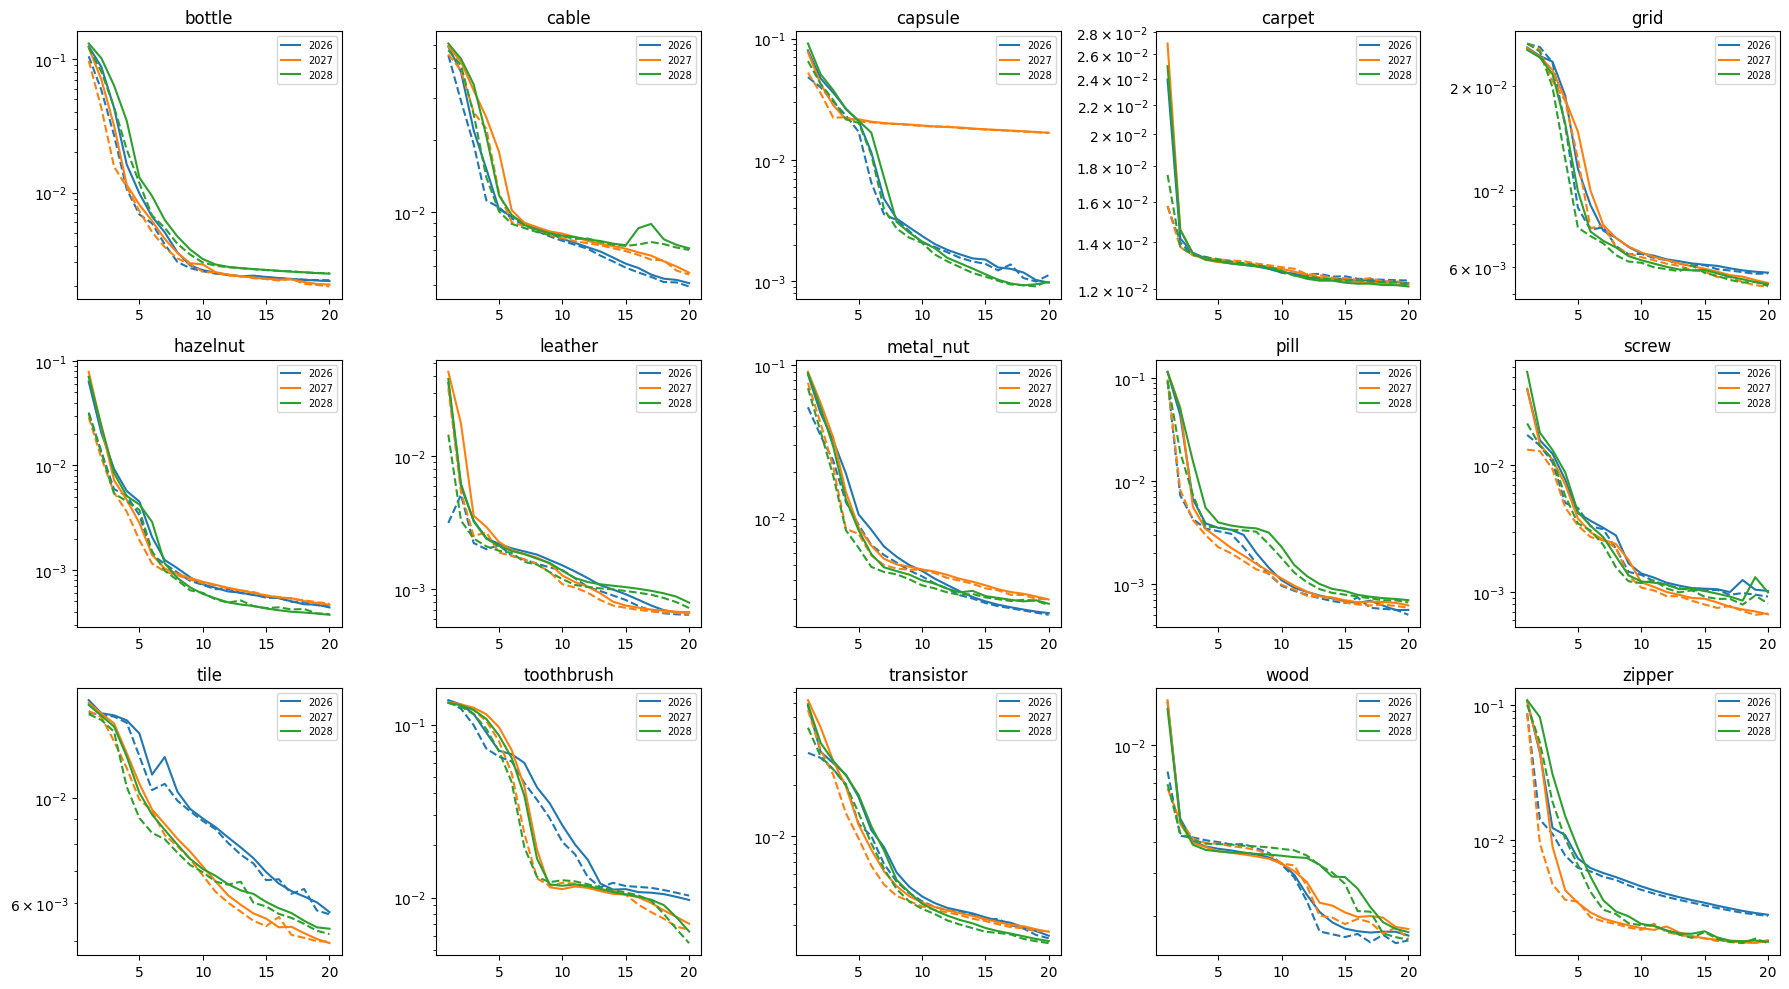

In [13]:
fig,axes=plt.subplots(3,5,figsize=(18,10))
for ax,category in zip(axes.flat,CATEGORIES):
    for seed in freeze['seeds']:
        h=pd.read_csv(report/f"runs/02-final-{freeze['selected_variant']}-{category}-s{seed}-v1-history.csv")
        line=ax.plot(h.epoch,h.train_loss,label=str(seed))[0]
        ax.plot(h.epoch,h.normal_development_loss,'--',color=line.get_color())
    ax.set_title(category);ax.legend(fontsize=7);ax.set_yscale('log')
plt.tight_layout();plt.show()


## Image ranking and calibration shift plots

These descriptive curves use seed 2026 throughout, never the best seed. Each
category's ROC and PR curve uses the retained official image scores. All-seed
metrics remain the primary tables. The calibration plots compare real calibration
normals against official test normals, with the frozen image threshold marked;
they reveal distribution shift without recalibrating on test data.


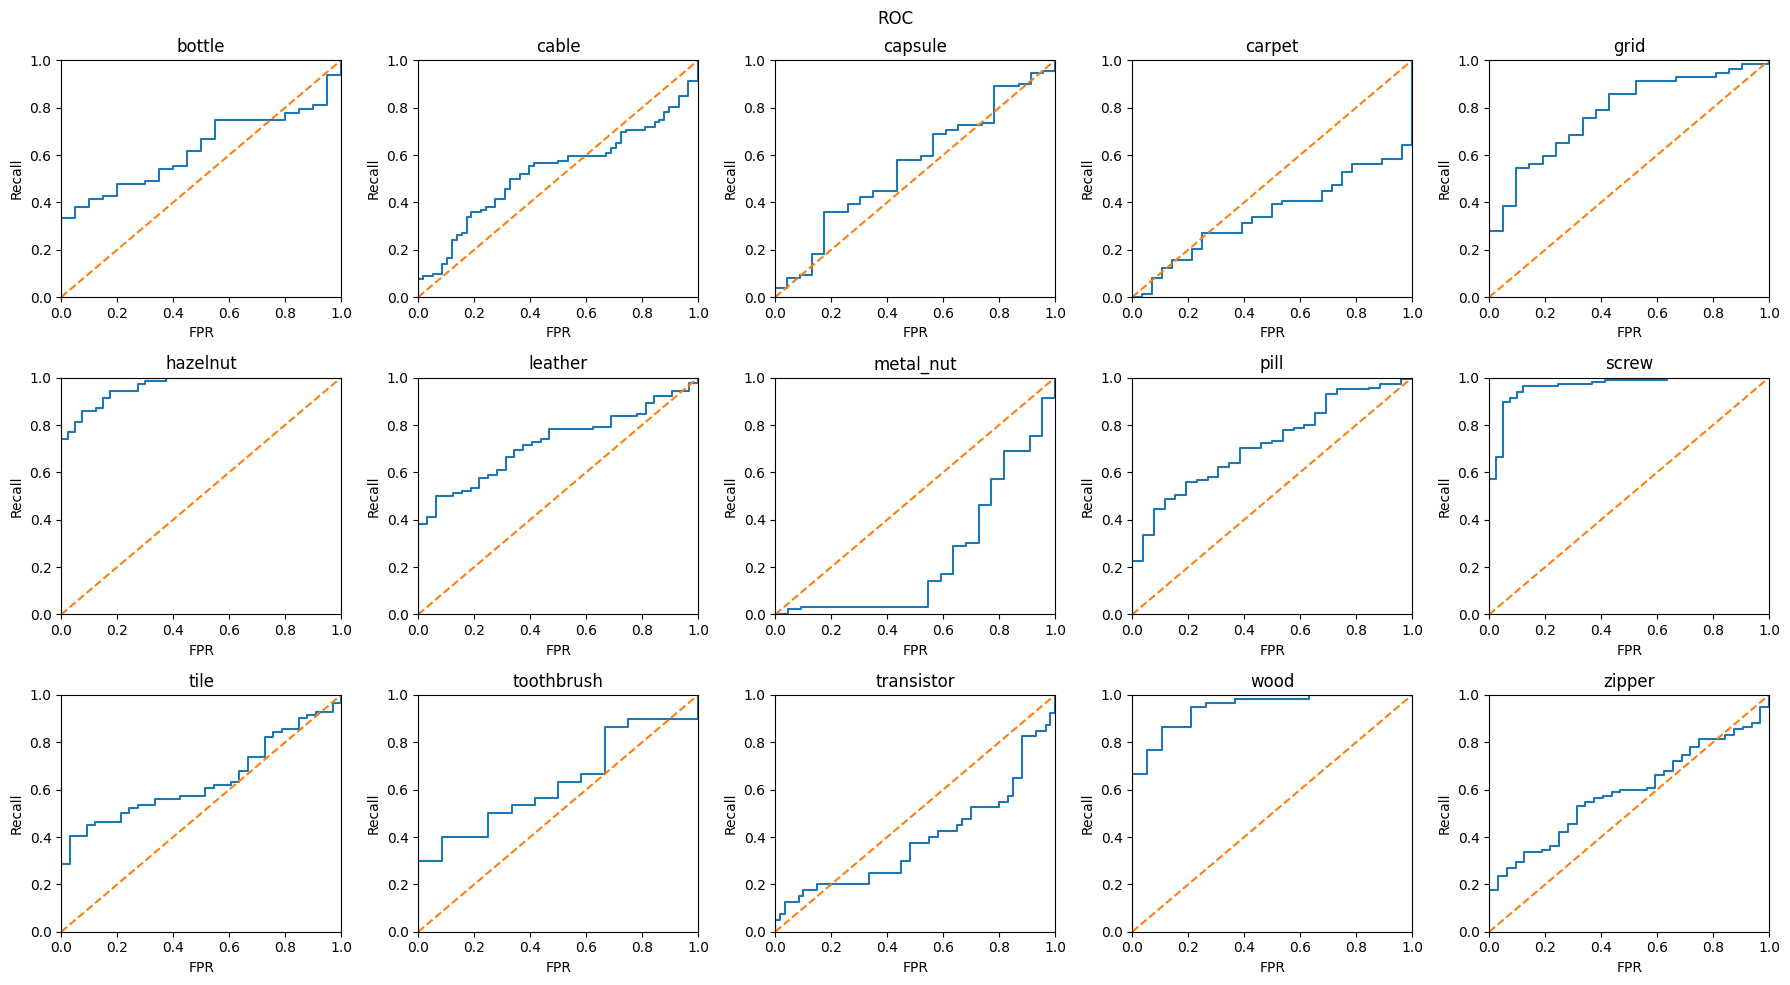

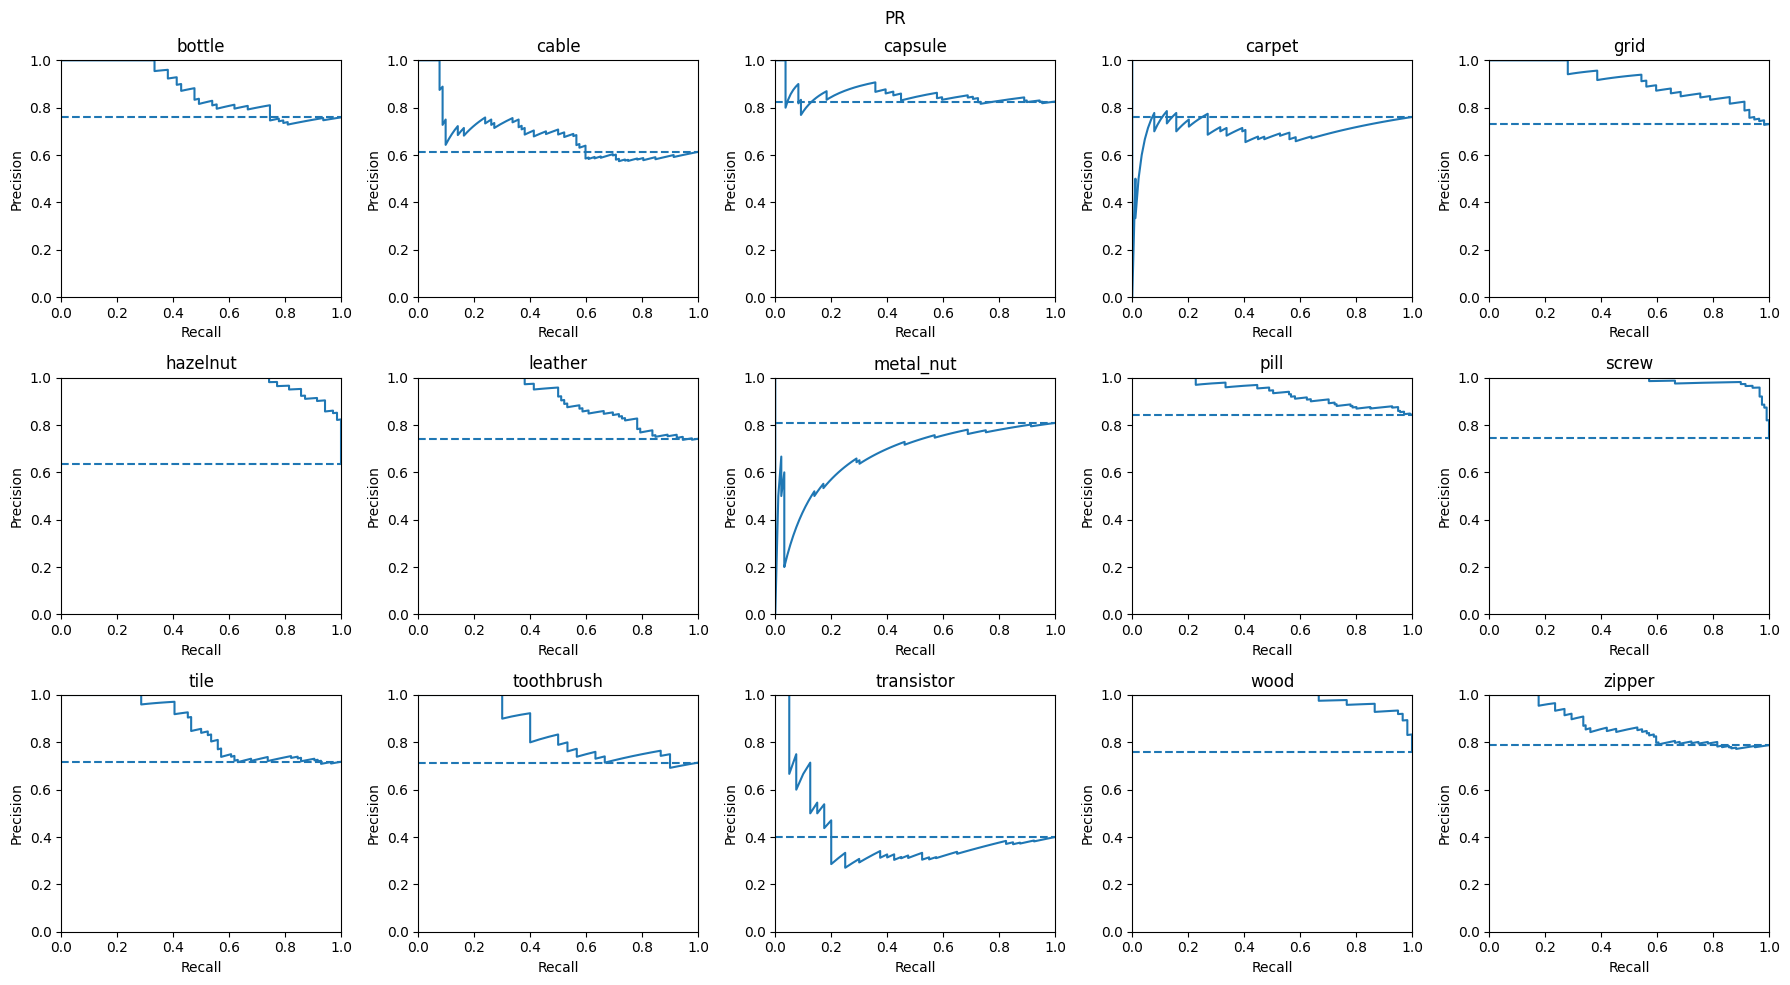

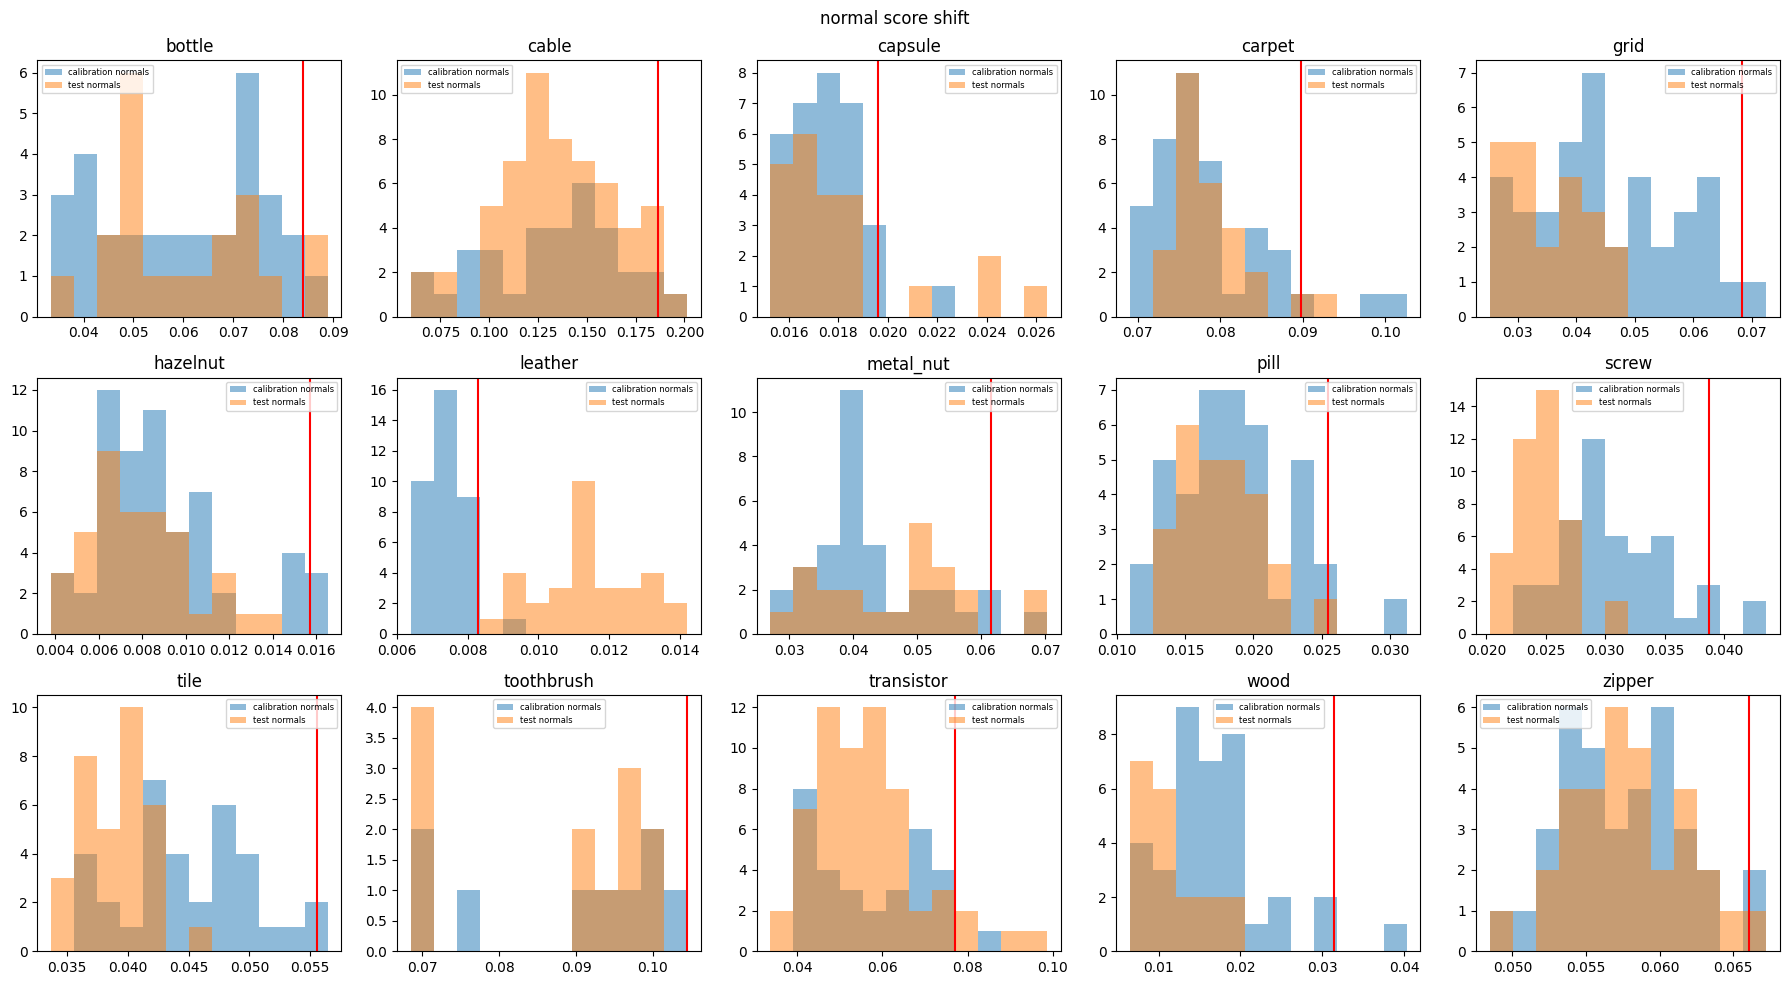

In [14]:
from sklearn.metrics import roc_curve,precision_recall_curve
for plot_kind in ['ROC','PR','normal score shift']:
    fig,axes=plt.subplots(3,5,figsize=(18,10))
    for ax,category in zip(axes.flat,CATEGORIES):
        identifier=f"02-test-{freeze['selected_variant']}-{category}-s2026-v1"
        t=pd.read_csv(report/f'evaluation/{identifier}-images.csv')
        c=json.loads((report/f'evaluation/{identifier}-calibration.json').read_text())
        if plot_kind=='ROC':
            fpr,tpr,_=roc_curve(t.label,t.score);ax.plot(fpr,tpr);ax.plot([0,1],[0,1],'--')
            ax.set_xlabel('FPR');ax.set_ylabel('Recall')
        elif plot_kind=='PR':
            precision,recall,_=precision_recall_curve(t.label,t.score);ax.plot(recall,precision)
            ax.axhline(t.label.mean(),linestyle='--');ax.set_xlabel('Recall');ax.set_ylabel('Precision')
        else:
            cal=np.asarray(c['calibration_scores'])
            normal=t.loc[t.label.eq(0),'score'].to_numpy()
            low=min(cal.min(),normal.min());high=max(cal.max(),normal.max())
            edges=np.linspace(low,max(high,low+1e-9),13)
            ax.hist(cal,bins=edges,alpha=.5,label='calibration normals')
            ax.hist(normal,bins=edges,alpha=.5,label='test normals')
            ax.axvline(c['image_threshold'],color='red');ax.legend(fontsize=6)
        if plot_kind in ['ROC','PR']:ax.set_xlim(0,1);ax.set_ylim(0,1)
        ax.set_title(category)
    fig.suptitle(plot_kind);plt.tight_layout();plt.show()


# Convolutional autoencoder: measured findings

The frozen shallow depth-3, width-16, latent-8 autoencoder used MSE, 256-square RGB,
20 fixed epochs, squared channel-mean residual maps and top-1% mean image scores.
All 15 categories completed seeds 2026/2027/2028. Calibration used only the
reserved normals. There was no post-test tuning or retraining.

| Metric | Autoencoder | Basic CNN | AE minus CNN |
|---|---:|---:|---:|
| image_auroc | 0.634623 | 0.712589 | -0.077966 |
| image_ap | 0.827916 | 0.858954 | -0.031038 |
| pixel_auroc | 0.690002 | 0.785832 | -0.095830 |
| pixel_ap | 0.110897 | 0.235382 | -0.124485 |
| au_pro | 0.449350 | 0.549807 | -0.100457 |
| recall | 0.235000 | 0.401760 | -0.166760 |
| fpr | 0.093944 | 0.098341 | -0.004397 |
| precision | 0.789620 | 0.873299 | -0.083679 |
| f1 | 0.314635 | 0.510593 | -0.195958 |

Image recall was 23.50% with test FPR 9.39%,
against a calibration image-FPR target of 5%. This is an empirical normal
quantile, not a guarantee under test distribution shift. Category/seed calibration
counts and threshold bootstrap intervals are retained in each evaluation record.
Two runs emitted no image alarms; primary macro precision follows the shared zero-division convention. Defined-run-only precision was 0.826347, reported separately.
The highest category image AUROC was hazelnut (0.9588);
the lowest was metal_nut (0.2388).

Texture image AUROC/recall: 0.6926 / 0.2865;
object image AUROC/recall: 0.6056 / 0.2092.
These are measured category summaries, not evidence that one architecture
mechanism alone causes the differences.

Mean per-run model-stage p50 was 2.871 ms versus CNN 3.139 ms;
end-to-end p50 was 13.272 ms versus 12.538 ms.
Both exclude file read/decode; AE model timing includes residual construction.
These are means of run percentiles, not pooled service latency.
Final training took 22.66 minutes including loading/validation.
Exact native evaluation took 58.70 minutes.
Peak allocated training VRAM was 0.607 GiB;
the model has 31,499 parameters and largest weight checkpoint 131,133 bytes.

## Failure evidence

Deterministically selected panels contain 15 false-negative examples; in 1,
mean residual inside the displayed defect mask was no larger than outside it.
The table and panel identify each image. Low inside/outside contrast, when
present, documents weak local separation. Other false negatives can have
higher local error but still fail image top-k aggregation or the normal threshold.
Selected false negatives had median top-1%-error/mask overlap 0.0518
and median overlap enrichment over mask-area fraction 2.222.
These display-resolution diagnostics distinguish dominant non-defect residuals
from errors at the actual defect; tiny mask area also limits achievable overlap.
0 selected false-negative masks disappeared under nearest-neighbor 256-square display resizing;
all primary localization metrics still used their original native masks.
Across the selected panels, median reconstructed/original neighbor-detail ratio was 0.434.
The lower neighbor-detail measure is consistent with blur in these selected reconstructions; it does not establish that blur alone causes missed defects.
The displayed normals had median residual on high-gradient pixels 0.006548
versus 0.001377 off those pixels.
These deliberately high-scoring normals expose normal-structure residuals;
they are not a random sample of normal reconstruction quality.

Directly inspected seed-2026 panels show the following concrete cases:

- `carpet/test/color/000.png`: the dark color defect is visibly retained in the reconstruction. Its mean in-mask residual is 0.002432 versus 0.010088 outside; normal weave errors dominate this false negative.
- `capsule/test/crack/000.png`: the small crack has weak residuals relative to normal printing and silhouette errors. Only 0.003049 of top-1%-error pixels overlap the displayed mask. Normal `good/002.png` is a false positive with visible printing/edge residuals.
- `metal_nut/test/good/009.png`: normal rims and surface detail produce a false-positive image score of 0.070304. The bent false negative `bent/000.png` retains its coarse altered contour and scores only 0.031789.
- `screw/test/scratch_head/003.png`: the image alarm is correct, but the overlay also marks normal threads; only 0.001524 of top-error pixels overlap the tiny displayed defect mask. Image detection success does not establish accurate localization.

Seed-2026 defect-size analysis (native mask area; descriptive, after freeze):

| Defect area | Images | Recall |
|---|---:|---:|
| at most 0.1% | 17 | 0.2353 |
| 0.1% to 1% | 482 | 0.2573 |
| above 1% | 759 | 0.2411 |

The smallest-group recall minus above-1%-group recall was -0.0058. Size groups mix categories and defect types; the table is descriptive rather than a matched resolution ablation.
256-square resizing and top-k dilution can suppress tiny defects in principle;
no higher-resolution counterfactual was trained after test to measure that effect.
See defect_type_size_summary.csv for scratch-specific counts and outcomes.

## Limits and retention

No pretrained features, skip connections, smoothing or combined loss were used.
The bounded development comparison selected MSE/squared residuals over the
four fixed object/texture categories. Proxy scores were modest and do not
guarantee transfer to real defects. Twenty epochs limit compute and do not
prove convergence for every category. Three seeds do not remove sampling
uncertainty. Small normal calibration partitions can yield unstable thresholds.
Pixel confidence intervals use fixed-bin whole-image bootstrap; point metrics
are exact at native resolution and quantization bias is separately reported.
Mean binned-minus-exact pixel AUROC bias was -0.008928,
with maximum absolute run difference 0.047090.
This is material: those intervals describe the binned approximation and must
not be treated as coverage intervals for the exact pixel AUROC point estimate.
Compare recall, FPR, pixel AP/AU-PRO and latency together before claiming an
improvement. This research benchmark does not establish production suitability.

The complete local notebook keeps original/reconstruction/error/overlay/mask
panels. Public outputs contain compact measured tables and aggregate plots.
Registry records are append-only, including all rejected variants. The pilot
executed live; later notebook cells analyze separately recorded jobs and
explicitly do not claim live training replay. No PatchCore work was started.


## Preservation and reproduction

All meaningful experiment starts/results/failures and the selection decision are
append-only JSON in [experiments](../experiments/). Configuration identities,
checkpoint/map/history hashes and compact real outputs are retained under
[reports/autoencoder](../reports/autoencoder/). Raw images, checkpoints, maps,
optimizer state and this notebook's full executed image panels remain ignored
locally. The public notebook strips only dataset-pixel panel outputs. It keeps
actual tables, plots and execution evidence. Training ran via
`scripts/run_autoencoder.py`; notebook analysis explicitly reads those artifacts.
Use new experiment IDs for reproductions; do not overwrite the v1 registry.
No post-test tuning/retraining or PatchCore work is part of this milestone.
Dataset attribution and license are retained in
[the project dataset documentation](../docs/dataset.md); MVTec image panels
remain local under the existing CC BY-NC-SA 4.0 retention policy.
